# Brain MRI Tumor Detection with Deep Learning

Binary classification of brain MRI scans (tumor vs. no tumor) using PyTorch. Two CNNs built from scratch are compared
with transfer learning on EfficientNet-B0, the best model is hyperparameter-tuned, and explainable AI methods
(Grad-CAM, Integrated Gradients, SHAP) are used to inspect where the model looks.

**Final model (tuned EfficientNet-B0) on the held-out test set (n = 34):**

| Accuracy | Sensitivity (recall) | Specificity | ROC-AUC |
|---|---|---|---|
| 94.1% | 100% (21/21 tumors detected) | 84.6% | 0.978 |

**Model comparison (test set):**

| # | Model | Accuracy | Sensitivity | Specificity | ROC-AUC |
|---|---|---|---|---|---|
| 1 | Scratch CNN (4 conv blocks) | 67.6% | 95.2% | 23.1% | 0.729 |
| 2 | Smaller scratch CNN (3 conv blocks) | 70.6% | 85.7% | 46.2% | 0.656 |
| 3 | EfficientNet-B0, ImageNet preprocessing | 88.2% | 85.7% | 92.3% | 0.974 |
| 4 | EfficientNet-B0, official preprocessing | 91.2% | 90.5% | 92.3% | 0.978 |
| 5 | **EfficientNet-B0, hyperparameter-tuned** | **94.1%** | **100%** | **84.6%** | **0.978** |

**Pipeline highlights**
- Removed 44 exact and near-duplicate images (MD5 + perceptual hashing) *before* splitting, to prevent train/test leakage
- Stratified 70/15/15 train/validation/test split, with class-imbalance handling (weighted loss and weighted sampling)
- Two-phase transfer learning (frozen backbone, then fine-tuning) and a 48-configuration grid search
- Explainable AI on true/false positives and negatives (see the known issue in Section 7)

**Dataset:** [Brain MRI Images for Brain Tumor Detection](https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection) (Navoneel Chakrabarty, Kaggle): 253 images, 209 after duplicate removal.

**Limitations:** The test set is small (34 images), so each misclassified image changes accuracy by about 3 percentage points.

## 1. Data Acquisition
**Dataset:** [Brain MRI Images for Brain Tumor Detection](https://www.kaggle.com/datasets/navoneel/brain-mri-images-for-brain-tumor-detection) (Navoneel Chakrabarty, Kaggle)

To run this notebook, download the dataset zip from the link above and place it in the same folder as this notebook.

In [ ]:
# Unzip the dataset into brain_mri_binary/ (works in any notebook environment)
import zipfile

with zipfile.ZipFile("brain-mri-images-for-brain-tumor-detection.zip") as z:
    z.extractall("brain_mri_binary")

DATA_DIR = "brain_mri_binary/brain_tumor_dataset"   # contains yes/ and no/

In [ ]:
# Count images per class (the folder name is the label: yes/ = tumor, no/ = no tumor)
import os

yes_count = len(os.listdir(os.path.join(DATA_DIR, "yes")))
no_count  = len(os.listdir(os.path.join(DATA_DIR, "no")))

print("Tumor (yes):  ", yes_count)
print("No tumor (no):", no_count)
print("Total images: ", yes_count + no_count)


Tumor (yes): 155
No tumor (no): 98
Total images: 253


## 2. Data Inspection

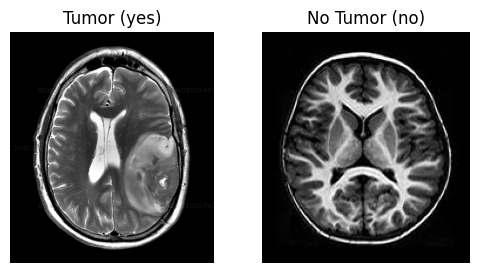

In [ ]:
# Visual confirmation of one image per class

import os
import matplotlib.pyplot as plt
from PIL import Image

yes_img_path = os.path.join(DATA_DIR, "yes", os.listdir(os.path.join(DATA_DIR, "yes"))[0])
no_img_path  = os.path.join(DATA_DIR, "no",  os.listdir(os.path.join(DATA_DIR, "no"))[0])

yes_img = Image.open(yes_img_path)
no_img  = Image.open(no_img_path)

plt.figure(figsize=(6,3))

plt.subplot(1,2,1)
plt.imshow(yes_img)
plt.title("Tumor (yes)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(no_img)
plt.title("No Tumor (no)")
plt.axis("off")

plt.show()


In [ ]:
# Check for stray files outside the class folders (these would have no label)
root_files = [f for f in os.listdir(DATA_DIR) if os.path.isfile(os.path.join(DATA_DIR, f))]
print("Files NOT inside class folders:", root_files)

Files NOT inside class folders: []


### Image validity check
Each image is opened and fully decoded to make sure none are corrupted, and sizes and aspect ratios are checked for extreme values.

In [ ]:
# Image validity checks:
#   1) PIL verify        - file integrity
#   2) PIL convert("RGB") - full decode + consistent color mode
#   3) Size sanity check  - flags images that are too small or too large
#   4) Aspect ratio check - flags extreme width/height ratios
#   5) TensorFlow decode  - second, independent decoder as a cross-check
from PIL import Image
import tensorflow as tf

classes = ["yes", "no"]

# Thresholds
MIN_SIZE = 32            # smaller than this is suspicious
MAX_SIZE = 3000          # larger than this is suspicious / heavy
ASPECT_RATIO_MAX = 4.0   # max(w, h) / min(w, h)

# Results
fail_verify, fail_rgb_convert, fail_tf_decode = [], [], []
bad_sizes, bad_aspects = [], []   # (path, (w, h)), (path, ratio)
total_files, checked_ok = 0, 0

for cls in classes:
    class_dir = os.path.join(DATA_DIR, cls)
    for file in os.listdir(class_dir):
        path = os.path.join(class_dir, file)
        if not os.path.isfile(path):
            continue

        total_files += 1
        ok = True

        # 1) File integrity (verify() makes the image unusable afterwards, so it's reopened below)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            fail_verify.append(path)
            ok = False

        # 2) Full decode to RGB, then 3) size and 4) aspect ratio checks
        try:
            img = Image.open(path).convert("RGB")
        except Exception:
            fail_rgb_convert.append(path)
            ok = False
        else:
            w, h = img.size
            if w < MIN_SIZE or h < MIN_SIZE or w > MAX_SIZE or h > MAX_SIZE:
                bad_sizes.append((path, (w, h)))
            ratio = max(w, h) / max(1, min(w, h))
            if ratio > ASPECT_RATIO_MAX:
                bad_aspects.append((path, ratio))

        # 5) Cross-check with TensorFlow's decoder
        try:
            tf.image.decode_image(tf.io.read_file(path))
        except Exception:
            fail_tf_decode.append(path)
            ok = False

        if ok:
            checked_ok += 1

# Summary report
print("========== Image Validity Report ==========")
print("DATA_DIR:", DATA_DIR)
print("Total files scanned:", total_files)
print("Passed ALL checks:", checked_ok)
print()

print("Failures:")
print("  PIL verify failed:          ", len(fail_verify))
print("  PIL convert/RGB failed:     ", len(fail_rgb_convert))
print("  TensorFlow decode failed:   ", len(fail_tf_decode))
print()

print("Sanity flags (not necessarily fatal):")
print("  Suspicious sizes:", len(bad_sizes), f"(min<{MIN_SIZE} or max>{MAX_SIZE})")
print("  Extreme aspect ratios:", len(bad_aspects), f"(>{ASPECT_RATIO_MAX})")

# Show the first few problem files, if any
for name, items in [("PIL verify failures", fail_verify),
                    ("PIL RGB/Load failures", fail_rgb_convert),
                    ("TF decode failures", fail_tf_decode),
                    ("Suspicious sizes", bad_sizes),
                    ("Extreme aspect ratios", bad_aspects)]:
    if items:
        print(f"\n--- {name} (showing up to 10) ---")
        for x in items[:10]:
            print(x)


========== Image Validity Report ==========
DATA_DIR: brain_mri_binary/brain_tumor_dataset
Total files scanned: 253
Passed ALL checks: 253

Failures:
  PIL verify failed:           0
  PIL convert/RGB failed:      0
  TensorFlow decode failed:    0

Sanity flags (not necessarily fatal):
  Suspicious sizes: 0 (min<32 or max>3000)
  Extreme aspect ratios: 0 (>4.0)


### Image sizes and file formats
CNNs need every input to be the same size, so this checks how much the sizes vary. Mixed file formats are fine as long as every file can be read.

In [ ]:
# Count image sizes and file extensions, per class and overall
from collections import Counter, defaultdict

size_per_class = defaultdict(Counter)
ext_per_class = defaultdict(Counter)
total_images = 0

for cls in classes:
    class_dir = os.path.join(DATA_DIR, cls)
    for file in os.listdir(class_dir):
        ext = os.path.splitext(file)[1].lower()
        try:
            with Image.open(os.path.join(class_dir, file)) as img:
                size_per_class[cls][img.size] += 1
                ext_per_class[cls][ext] += 1
                total_images += 1
        except Exception:
            print(f"Skipping unreadable image: {file}")

# Per class
for cls in classes:
    print(f"\nClass: {cls.upper()}")
    print("Total images:", sum(size_per_class[cls].values()))
    print("Image sizes:")
    for size, count in size_per_class[cls].items():
        print(f"  {size}: {count}")
    print("Image extensions:")
    for ext, count in ext_per_class[cls].items():
        print(f"  {ext}: {count}")

# Overall
overall_sizes, overall_exts = Counter(), Counter()
for cls in classes:
    overall_sizes.update(size_per_class[cls])
    overall_exts.update(ext_per_class[cls])

print("\nOVERALL DATASET SUMMARY")
print("Total images:", total_images)
print("\nAll image sizes:")
for size, count in overall_sizes.items():
    print(f"  {size}: {count}")
print("\nAll image extensions:")
for ext, count in overall_exts.items():
    print(f"  {ext}: {count}")


Class: YES
Total images: 155
Image sizes:
  (1059, 1200): 2
  (300, 325): 4
  (201, 251): 2
  (289, 315): 1
  (260, 331): 1
  (273, 351): 1
  (911, 938): 3
  (287, 348): 1
  (864, 938): 1
  (512, 512): 3
  (294, 380): 1
  (244, 308): 1
  (400, 431): 2
  (313, 360): 1
  (310, 380): 3
  (290, 355): 1
  (249, 269): 1
  (264, 338): 1
  (225, 225): 2
  (300, 359): 1
  (314, 340): 2
  (250, 294): 2
  (320, 355): 1
  (229, 270): 1
  (433, 520): 1
  (1275, 1427): 1
  (300, 336): 1
  (258, 279): 1
  (630, 630): 4
  (254, 325): 2
  (278, 324): 1
  (262, 351): 1
  (224, 245): 1
  (297, 359): 1
  (211, 239): 1
  (293, 337): 1
  (300, 349): 1
  (248, 338): 1
  (400, 369): 1
  (253, 291): 1
  (236, 278): 1
  (272, 277): 1
  (294, 355): 1
  (620, 620): 2
  (1061, 1280): 1
  (200, 253): 1
  (283, 357): 1
  (272, 331): 1
  (209, 212): 1
  (353, 442): 1
  (240, 300): 2
  (450, 446): 2
  (300, 347): 1
  (189, 173): 1
  (283, 334): 1
  (291, 340): 1
  (273, 318): 1
  (223, 303): 1
  (281, 352): 1
  (204,

**Findings**
- All 253 images are readable. None are corrupted.
- **Class balance:** 155 tumor (61%) vs. 98 no tumor (39%), a mild imbalance.
- **Sizes vary a lot:** there are 184 different image sizes, ranging from 150 px to 1,920 px. Every image will be resized to 224×224 before training.
- **File formats:** 245 `.jpg`, 6 `.jpeg`, 2 `.png`. Mixed formats are fine because all of them load correctly.

## 3. Data Cleaning: Removing Duplicates
The biggest risks in a small medical image dataset are:
1. **Data leakage from duplicates:** if the same scan ends up in both training and test sets, the test score is inflated.
2. **Inconsistent inputs:** mixed image sizes and color modes.
3. **Label quality:** images placed in the wrong class folder.

Duplicates are moved to a quarantine folder rather than deleted, so they can be reviewed later.

In [ ]:
# Find exact duplicates: byte-identical files have the same MD5 hash
import hashlib

def file_md5(path, chunk=8192):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

hash_to_paths = defaultdict(list)
for cls in classes:
    class_dir = os.path.join(DATA_DIR, cls)
    for fn in os.listdir(class_dir):
        p = os.path.join(class_dir, fn)
        if os.path.isfile(p):
            hash_to_paths[file_md5(p)].append(p)

dupes = {h: ps for h, ps in hash_to_paths.items() if len(ps) > 1}
print("Exact duplicate groups:", len(dupes))
for i, ps in enumerate(dupes.values(), start=1):
    print(f"\nDuplicate group {i} ({len(ps)} files):")
    for p in ps:
        print("  ", p)

Exact duplicate groups: 22

Duplicate group 1 (2 files):
   brain_mri_binary/brain_tumor_dataset/yes/Y162.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y108.jpg

Duplicate group 2 (4 files):
   brain_mri_binary/brain_tumor_dataset/yes/Y38.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y30.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y70.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y54.jpg

Duplicate group 3 (2 files):
   brain_mri_binary/brain_tumor_dataset/yes/Y107.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y33.jpg

Duplicate group 4 (2 files):
   brain_mri_binary/brain_tumor_dataset/yes/Y154.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y79.jpg

Duplicate group 5 (3 files):
   brain_mri_binary/brain_tumor_dataset/yes/Y34.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y181.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y15.jpg

Duplicate group 6 (2 files):
   brain_mri_binary/brain_tumor_dataset/yes/Y62.jpg
   brain_mri_binary/brain_tumor_dataset/yes/Y31.jpg

Duplica

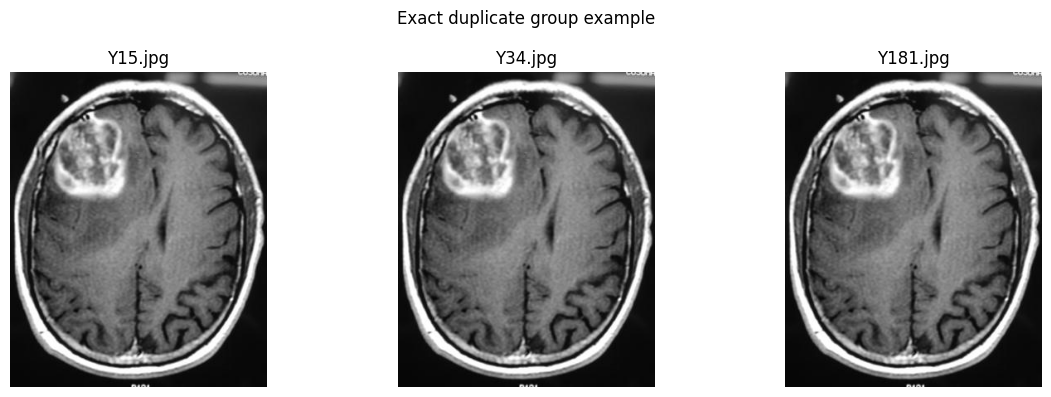

In [ ]:
# Show one exact-duplicate group side by side (group 5 above: Y15, Y34, Y181)
def show_images(paths, title):
    plt.figure(figsize=(4 * len(paths), 4))
    for i, p in enumerate(paths, start=1):
        plt.subplot(1, len(paths), i)
        plt.imshow(Image.open(p), cmap="gray")
        plt.title(os.path.basename(p))
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_images([os.path.join(DATA_DIR, "yes", f) for f in ["Y15.jpg", "Y34.jpg", "Y181.jpg"]],
            title="Exact duplicate group example")


In [ ]:
# Quarantine exact duplicates: keep one file per group, move the rest
import shutil

QUAR_DIR = os.path.join(os.path.dirname(DATA_DIR), "duplicates_quarantine")
os.makedirs(QUAR_DIR, exist_ok=True)

print("Exact duplicate groups:", len(dupes))

moved = 0
for paths in dupes.values():
    for p in sorted(paths)[1:]:   # keep the first file (alphabetically), move the others
        dest = os.path.join(QUAR_DIR, os.path.relpath(p, DATA_DIR).replace(os.sep, "__"))
        shutil.move(p, dest)
        moved += 1

print("Moved duplicate files to quarantine:", moved)
print("Quarantine folder:", QUAR_DIR)

Exact duplicate groups: 22
Moved duplicate files to quarantine: 25
Quarantine folder: brain_mri_binary/duplicates_quarantine


In [ ]:
# Confirm the quarantine worked and count the remaining images
print("Quarantine folder exists:", os.path.exists(QUAR_DIR))
print("Total files in quarantine:", sum(len(files) for _, _, files in os.walk(QUAR_DIR)))

yes_count = len(os.listdir(os.path.join(DATA_DIR, "yes")))
no_count  = len(os.listdir(os.path.join(DATA_DIR, "no")))
print("yes:", yes_count, "no:", no_count)
print("Total images:", yes_count + no_count)


Quarantine folder exists: True
Total files in quarantine: 25
yes: 141 no: 87
Total images: 228


In [ ]:
# Find near-duplicates: the same scan saved with different compression, size or crop.
# Perceptual hashes (pHash) of near-identical images differ by only a few bits.
!pip -q install imagehash
import imagehash
from pathlib import Path

NEAR_DUP_THRESHOLD = 2   # max bit difference between two hashes to count as near-duplicates
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
DUP_NEAR_DIR = Path("brain_mri_binary/duplicates_near_quarantine")
DUP_NEAR_DIR.mkdir(parents=True, exist_ok=True)

# Images left after exact-duplicate removal
paths = [p for cls in classes for p in (Path(DATA_DIR) / cls).rglob("*")
         if p.is_file() and p.suffix.lower() in IMG_EXTS]
print("Images scanned:", len(paths))

# Hash every image
p_to_h, bad = {}, []
for p in paths:
    try:
        with Image.open(p) as img:
            p_to_h[p] = imagehash.phash(img.convert("RGB"))
    except Exception as e:
        bad.append((p, str(e)))

print("Hashed:", len(p_to_h), "| bad:", len(bad))
if bad:
    print("Example bad:", bad[0])

paths = list(p_to_h)
hashes = [p_to_h[p] for p in paths]

# Group images whose hashes are close (union-find: if A~B and B~C, then A, B, C form one group)
parent = list(range(len(paths)))

def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

for i in range(len(paths)):
    for j in range(i + 1, len(paths)):
        if hashes[i] - hashes[j] <= NEAR_DUP_THRESHOLD:
            parent[find(j)] = find(i)

groups = defaultdict(list)
for i, p in enumerate(paths):
    groups[find(i)].append(p)
near_groups = [g for g in groups.values() if len(g) > 1]

print("Near-duplicate groups:", len(near_groups))
print("Total files involved in near-dups:", sum(len(g) for g in near_groups))
print("Files that would be moved (keep 1/group):", sum(len(g) - 1 for g in near_groups))

for gi, grp in enumerate(near_groups, start=1):
    print(f"\nGroup {gi} (n={len(grp)}):")
    for p in grp:
        print(" ", p)




   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 6.4 MB/s eta 0:00:00
Images scanned: 228
Hashed: 228 | bad: 0
Near-duplicate groups: 18
Total files involved in near-dups: 37
Files that would be moved (keep 1/group): 19

Group 1 (n=2):
  brain_mri_binary/brain_tumor_dataset/yes/Y92.png
  brain_mri_binary/brain_tumor_dataset/yes/Y20.jpg

Group 2 (n=2):
  brain_mri_binary/brain_tumor_dataset/yes/Y153.jpg
  brain_mri_binary/brain_tumor_dataset/yes/Y105.jpg

Group 3 (n=2):
  brain_mri_binary/brain_tumor_dataset/yes/Y91.jpg
  brain_mri_binary/brain_tumor_dataset/yes/Y21.jpg

Group 4 (n=2):
  brain_mri_binary/brain_tumor_dataset/yes/Y156.JPG
  brain_mri_binary/brain_tumor_dataset/yes/Y60.jpg

Group 5 (n=2):
  brain_mri_binary/brain_tumor_dataset/yes/Y52.jpg
  brain_mri_binary/brain_tumor_dataset/yes/Y6.jpg

Group 6 (n=2):
  brain_mri_binary/brain_tumor_dataset/yes/Y35.jpg
  brain_mri_binary/brain_tumor_dataset/yes/Y8.jpg

Group 7 (n=2):
  brain_mri_binary/brain_tumor_dataset/yes/Y7

In [ ]:
# Plot near-duplicate groups so each one can be checked by eye before quarantine
import math

def show_near_group(group_paths, group_idx=None, max_cols=4):
    n = len(group_paths)
    cols = min(max_cols, n)
    rows = math.ceil(n / cols)

    plt.figure(figsize=(3.5 * cols, 3.5 * rows))
    for i, p in enumerate(group_paths, start=1):
        plt.subplot(rows, cols, i)
        plt.imshow(Image.open(p), cmap="gray")
        plt.title(os.path.basename(p), fontsize=9)
        plt.axis("off")

    title = f"Near-Duplicate Group {group_idx} (n={n})" if group_idx else "Near-Duplicate Group"
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

def show_all_near_groups(near_groups):
    for i, group in enumerate(near_groups, start=1):
        show_near_group(group, group_idx=i)

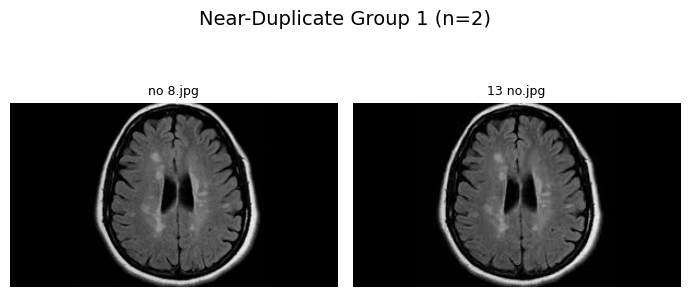

In [ ]:
# Visualize a single near-duplicate group
show_near_group(near_groups[9], group_idx=1)


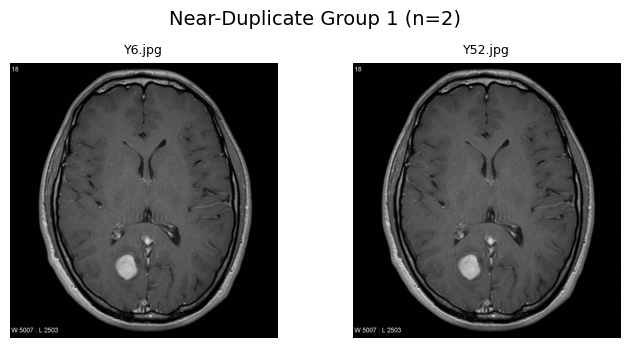

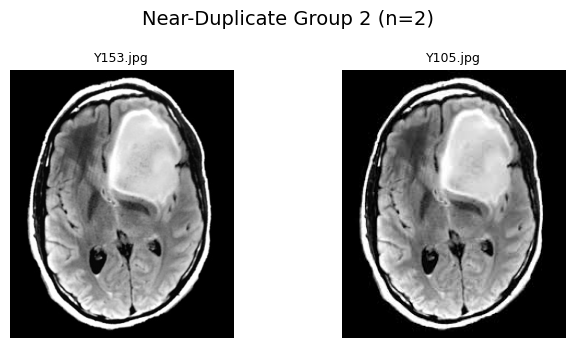

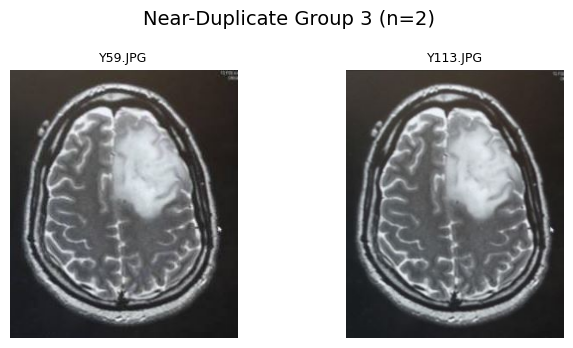

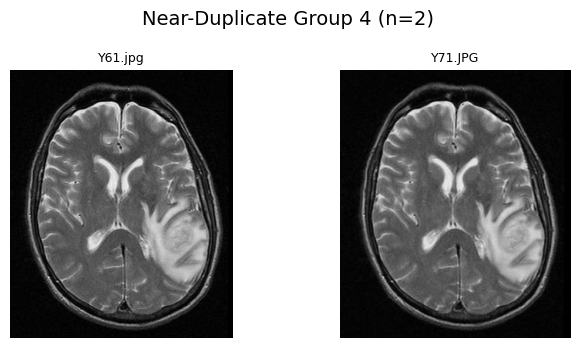

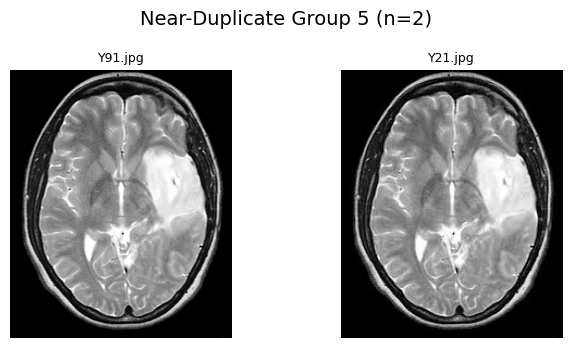

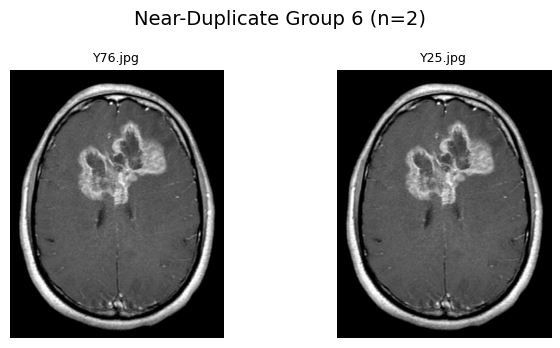

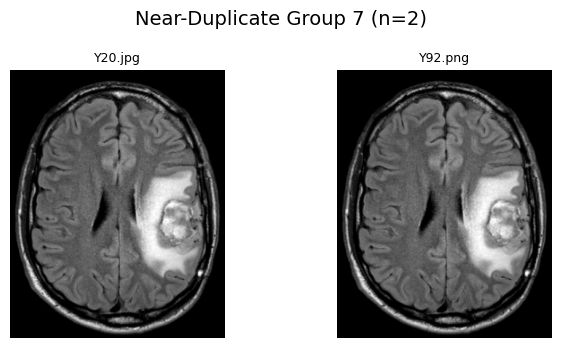

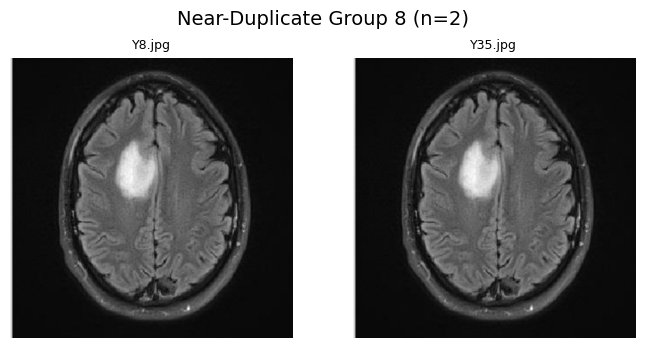

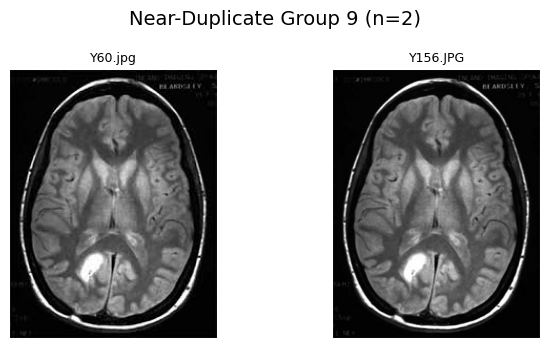

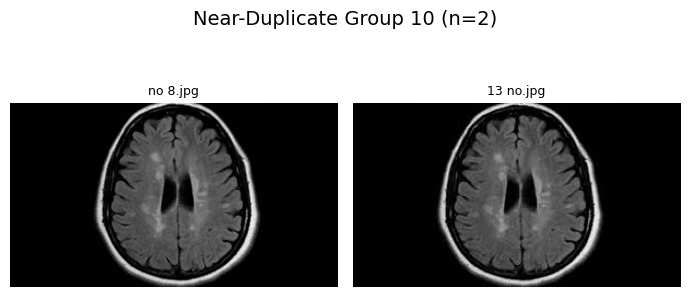

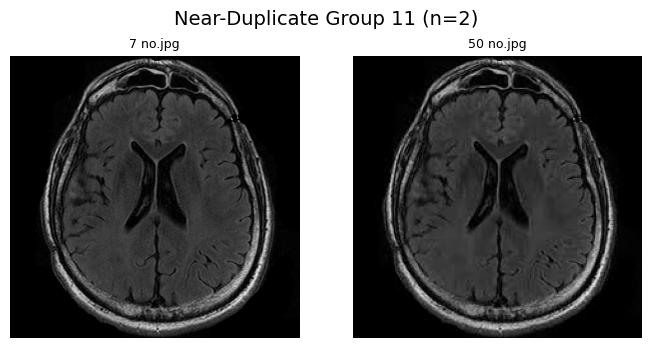

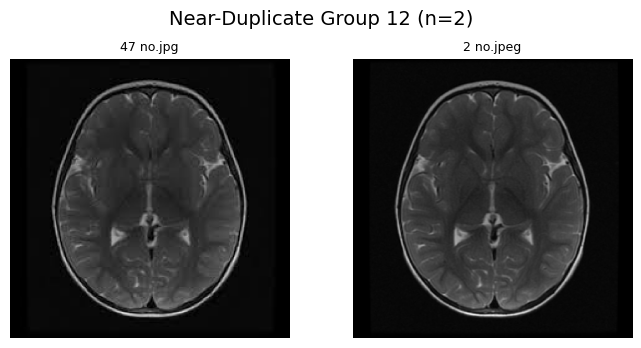

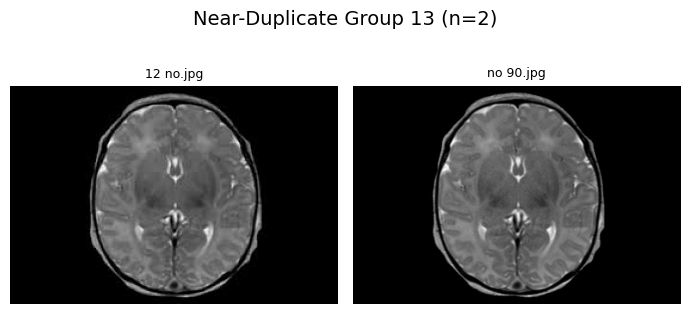

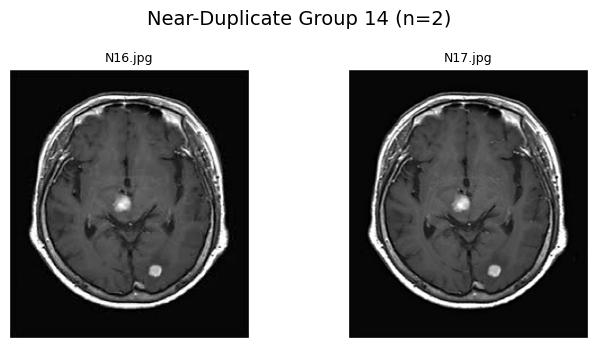

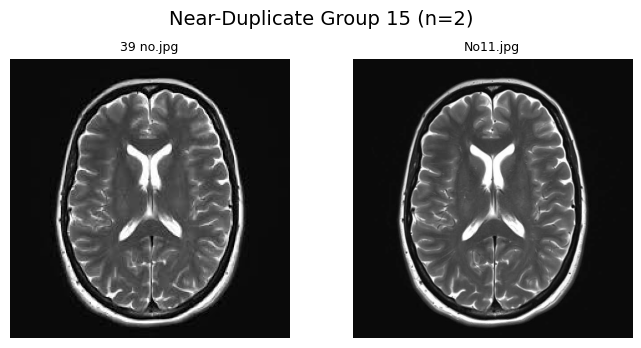

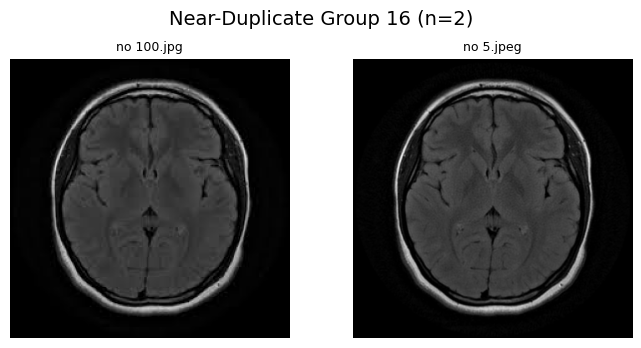

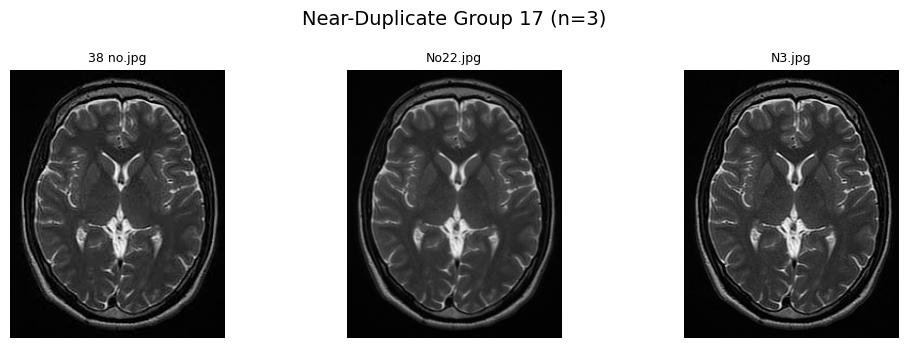

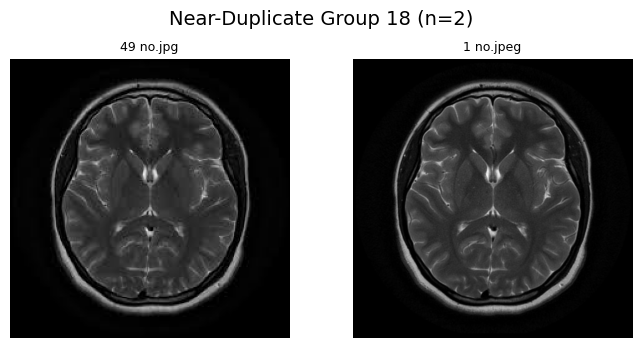

In [ ]:
# Visualize all near-duplicate groups
show_all_near_groups(near_groups)

# Near-duplicate images were identified using perceptual hashing with a Hamming-distance threshold and visually verified before quarantine.


In [ ]:
# Quarantine near-duplicates: keep one file per group, move the rest
moved = []
for grp in near_groups:
    keep = sorted(grp)[0]   # deterministic choice of which file to keep
    for dup in grp:
        if dup == keep:
            continue
        target = DUP_NEAR_DIR / dup.relative_to(DATA_DIR)
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(dup), str(target))
        moved.append((dup, keep))

print("\nMoved near-duplicate files:", len(moved))
print("Near-dup quarantine:", DUP_NEAR_DIR)


Moved near-duplicate files: 19
Near-dup quarantine: brain_mri_binary/duplicates_near_quarantine


In [ ]:
# Confirm the near-duplicate quarantine worked and count the remaining images
print("Quarantine folder exists:", os.path.exists(DUP_NEAR_DIR))
print("Total files in quarantine:", sum(len(files) for _, _, files in os.walk(DUP_NEAR_DIR)))

yes_count = len(os.listdir(os.path.join(DATA_DIR, "yes")))
no_count  = len(os.listdir(os.path.join(DATA_DIR, "no")))
print("yes:", yes_count, "no:", no_count)
print("Total images:", yes_count + no_count)

Quarantine folder exists: True
Total files in quarantine: 19
yes: 132 no: 77
Total images: 209


**Findings**
- **Exact duplicates:** 22 groups found with MD5 hashing; 25 extra copies quarantined.
- **Near-duplicates:** 18 groups found with perceptual hashing (Hamming distance ≤ 2) and checked visually; 19 extra copies quarantined.
- **In total, 44 duplicate images (17%) were removed** before splitting, so the same scan can't end up in both the training and test sets.
- **Remaining dataset:** 209 images (132 tumor, 77 no tumor).

In [ ]:
# Check image sizes and color modes on the cleaned dataset
sizes, modes, bad = Counter(), Counter(), []

for cls in classes:
    class_dir = os.path.join(DATA_DIR, cls)
    for fn in os.listdir(class_dir):
        p = os.path.join(class_dir, fn)
        try:
            with Image.open(p) as img:
                sizes[img.size] += 1   # (width, height)
                modes[img.mode] += 1   # 'L', 'RGB', etc.
        except Exception:
            bad.append(p)

print("Unreadable images:", len(bad))
print("\nTop image sizes:")
for s, c in sizes.most_common(10):
    print(s, c)
print("\nImage modes:")
for m, c in modes.most_common():
    print(m, c)


Unreadable images: 0

Top image sizes:
(225, 225) 14
(630, 630) 7
(201, 251) 4
(512, 512) 3
(442, 442) 3
(232, 217) 3
(314, 340) 2
(911, 938) 2
(272, 350) 2
(1024, 1024) 2

Image modes:
RGB 185
L 19
RGBA 4
P 1


**Findings:** The 209 remaining images come in four color modes: RGB (185), grayscale `L` (19), `RGBA` (4) and palette `P` (1).
The models need a consistent input, so every image is converted to RGB (3 channels) and resized to 224×224 in the preprocessing step

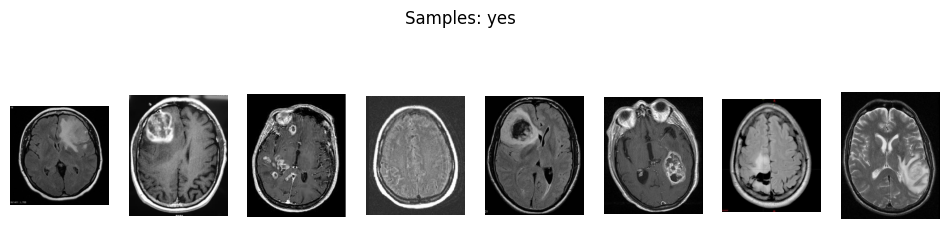

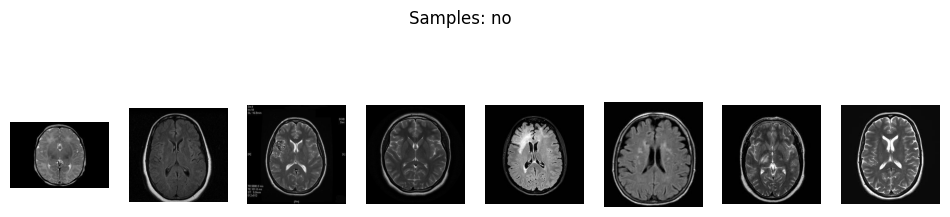

In [ ]:
# Label spot check: random samples from each class (seeded so the same images show every run)
import random

def show_samples(cls, n=8, seed=42):
    files = os.listdir(os.path.join(DATA_DIR, cls))
    sample = random.Random(seed).sample(files, min(n, len(files)))
    plt.figure(figsize=(12, 3))
    for i, f in enumerate(sample, start=1):
        plt.subplot(1, len(sample), i)
        plt.imshow(Image.open(os.path.join(DATA_DIR, cls, f)).convert("RGB"))
        plt.axis("off")
    plt.suptitle(f"Samples: {cls}")
    plt.show()

show_samples("yes")
show_samples("no")



**Label quality:** Tumors often show up as bright or irregular regions, which is consistent with the samples above.

**Limitation:** Confirming that every image is in the correct class folder requires a radiologist, so labels are taken as provided by the dataset.

In [ ]:
#  Check class imbalance
yes_n = len(os.listdir(f"{DATA_DIR}/yes"))
no_n  = len(os.listdir(f"{DATA_DIR}/no"))
total = yes_n + no_n
print("Yes %:", yes_n/total, "No %:", no_n/total)

# Yes Tumor: 63%
# No Tumor : 37%
# Mild imbalance

Yes %: 0.631578947368421 No %: 0.3684210526315789


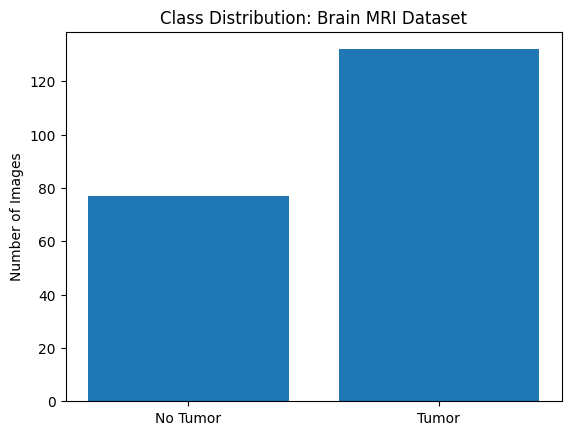

In [ ]:
# Visualize
import matplotlib.pyplot as plt

labels = ["No Tumor", "Tumor"]
counts = [no_count, yes_count]

plt.bar(labels, counts)
plt.title("Class Distribution: Brain MRI Dataset")
plt.ylabel("Number of Images")
plt.show()


## 4. Preprocessing: Split, Resize, Normalize, Augment
The cleaned dataset is split into train (70%), validation (15%) and test (15%) sets, stratified so each set keeps the same tumor / no-tumor ratio.
Images are converted to RGB, resized to 224×224 and normalized with ImageNet statistics. The training set also gets light augmentation (random flips and small rotations).

In [ ]:
# Step 1: DataSet Split
# Stratified train/val/test split for ImageFolder-style dataset
# Creates NEW folders:
    # brain_mri_binary/splits/train/{no,yes}
    # brain_mri_binary/splits/val/{no,yes}
    # brain_mri_binary/splits/test/{no,yes}
# This prevents leakage from random sampling and keeps class proportions similar.

import os, shutil, random
from pathlib import Path
from collections import Counter

DATA_DIR = Path("brain_mri_binary/brain_tumor_dataset")  # contains yes/ and no/
OUT_DIR  = Path("brain_mri_binary/splits")

classes = ["no", "yes"]  # based on mapping {'no':0, 'yes':1}

# Split ratios (common choice)
train_ratio = 0.70
val_ratio   = 0.15
test_ratio  = 0.15

assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-9, "Ratios must sum to 1."

# Reproducibility
seed = 42
random.seed(seed)

# Fresh output folders (delete old splits if they exist)
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)

for split in ["train", "val", "test"]:
    for cls in classes:
        (OUT_DIR / split / cls).mkdir(parents=True, exist_ok=True)

# Helper: list only image files
valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def list_images(class_dir: Path):
    return sorted([p for p in class_dir.iterdir() if p.suffix.lower() in valid_ext and p.is_file()])

# Perform stratified split per class
split_counts = { "train": Counter(), "val": Counter(), "test": Counter() }

for cls in classes:
    paths = list_images(DATA_DIR / cls)
    n = len(paths)
    if n == 0:
        raise ValueError(f"No images found in class folder: {DATA_DIR / cls}")

    # shuffle deterministically
    # We shuffle deterministically during splitting to ensure the train/validation/test sets are random but reproducible, preventing bias
    # while allowing experiments to be repeated and verified

    random.shuffle(paths)

    n_train = int(n * train_ratio)
    n_val   = int(n * val_ratio)
    n_test  = n - n_train - n_val  # remainder

    train_paths = paths[:n_train]
    val_paths   = paths[n_train:n_train+n_val]
    test_paths  = paths[n_train+n_val:]

    # Copy files into split folders
    for p in train_paths:
        shutil.copy2(p, OUT_DIR / "train" / cls / p.name)
    for p in val_paths:
        shutil.copy2(p, OUT_DIR / "val" / cls / p.name)
    for p in test_paths:
        shutil.copy2(p, OUT_DIR / "test" / cls / p.name)

    split_counts["train"][cls] += len(train_paths)
    split_counts["val"][cls]   += len(val_paths)
    split_counts["test"][cls]  += len(test_paths)

# Print split summary
print("Split created at:", OUT_DIR)
print("\nCounts per split:")
for split in ["train", "val", "test"]:
    total = sum(split_counts[split].values())
    print(f"  {split:5s} -> {dict(split_counts[split])} | total={total}")

# Quick sanity checks: totals should match original counts
orig_counts = {cls: len(list_images(DATA_DIR / cls)) for cls in classes}
new_counts  = {cls: (split_counts["train"][cls] + split_counts["val"][cls] + split_counts["test"][cls]) for cls in classes}

print("\nOriginal counts:", orig_counts)
print("Split totals   :", new_counts)

assert orig_counts == new_counts, "Mismatch between original counts and split totals!"

# Optional: show class proportions per split

def proportions(counts: Counter):
    total = sum(counts.values())
    return {k: round(v/total, 3) for k, v in counts.items()}

print("\nClass proportions per split:")
for split in ["train", "val", "test"]:
    print(f"  {split:5s} -> {proportions(split_counts[split])}")



Split created at: brain_mri_binary/splits

Counts per split:
  train -> {'no': 53, 'yes': 92} | total=145
  val   -> {'no': 11, 'yes': 19} | total=30
  test  -> {'no': 13, 'yes': 21} | total=34

Original counts: {'no': 77, 'yes': 132}
Split totals   : {'no': 77, 'yes': 132}

Class proportions per split:
  train -> {'no': 0.366, 'yes': 0.634}
  val   -> {'no': 0.367, 'yes': 0.633}
  test  -> {'no': 0.382, 'yes': 0.618}


In [ ]:
# Step 2: Build datasets/loaders from the split folders + transforms
# A. Transform
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

SPLIT_DIR = "brain_mri_binary/splits"
train_dir = os.path.join(SPLIT_DIR, "train")
val_dir   = os.path.join(SPLIT_DIR, "val")
test_dir  = os.path.join(SPLIT_DIR, "test")

train_tfms = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])


In [ ]:
# B. Datasets + loaders



SPLIT_DIR = "brain_mri_binary/splits"
train_dir = os.path.join(SPLIT_DIR, "train")
val_dir   = os.path.join(SPLIT_DIR, "val")

train_ds = datasets.ImageFolder(train_dir, transform=train_tfms)
val_ds   = datasets.ImageFolder(val_dir,   transform=eval_tfms)
test_ds  = datasets.ImageFolder(test_dir,  transform=eval_tfms)

print("class_to_idx:", train_ds.class_to_idx)  # expected {'no':0,'yes':1}

pin = torch.cuda.is_available()

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2, pin_memory=pin)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2, pin_memory=pin)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2, pin_memory=pin)

# quick sanity check
x, y = next(iter(train_loader))
print("Batch:", x.shape, y.shape)  # [B, 3, 224, 224], [B]


class_to_idx: {'no': 0, 'yes': 1}
Batch: torch.Size([32, 3, 224, 224]) torch.Size([32])


In [ ]:
# confirm transformation
x, y = next(iter(train_loader))
print("Images shape:", x.shape)    # [B, 3, 224, 224]
print("Images dtype:", x.dtype)    # torch.float32
print("Labels shape:", y.shape)    # [B]
print("Unique labels:", y.unique())


Images shape: torch.Size([32, 3, 224, 224])
Images dtype: torch.float32
Labels shape: torch.Size([32])
Unique labels: tensor([0, 1])


In [ ]:
# Confirm loaders/transforms are working + confirm ONLY RGB (3 channels) is being fed to the model

import torch
import numpy as np

# 1) Grab a batch
x, y = next(iter(train_loader))

print("Images shape:", x.shape)      # expected: [B, 3, 224, 224]
print("Images dtype:", x.dtype)      # expected: torch.float32
print("Labels shape:", y.shape)      # expected: [B]
print("Unique labels:", y.unique())  # expected: tensor([0, 1]) (order may vary)

# 2) Confirm "mode" at the model-input level:
#    If x.shape[1] == 3, then the batch is RGB (3 channels) after convert("RGB")
channels = x.shape[1]
mode = "RGB" if channels == 3 else ("L (grayscale)" if channels == 1 else f"{channels}-channel")
print("Input mode (based on tensor channels):", mode)

if channels != 3:
    print(" Not RGB. Check your transforms include: transforms.Lambda(lambda img: img.convert('RGB'))")
else:
    print("All inputs are RGB (3 channels).")

# 3) Optional: numeric proof normalization happened (values typically not confined to [0,1])
print("Pixel min/max/mean:", x.min().item(), x.max().item(), x.mean().item())

# 4) Optional: verify a few items by applying a reverse-normalization and plotting (requires your denorm function)
#    (If you already have denorm + matplotlib block, you can keep using it.)


Images shape: torch.Size([32, 3, 224, 224])
Images dtype: torch.float32
Labels shape: torch.Size([32])
Unique labels: tensor([0, 1])
Input mode (based on tensor channels): RGB
All inputs are RGB (3 channels).
Pixel min/max/mean: -2.1179039478302 2.640000104904175 -0.6022038459777832


In [ ]:
print("Pixel min:", x.min().item())
print("Pixel max:", x.max().item())
print("Pixel mean:", x.mean().item())


Pixel min: -2.1179039478302
Pixel max: 2.640000104904175
Pixel mean: -0.6022038459777832


In [ ]:
# check per-channel mean and SD
# x shape: [B, C, H, W]
batch_mean = x.mean(dim=[0,2,3])
batch_std  = x.std(dim=[0,2,3])

print("Per-channel mean:", batch_mean)
print("Per-channel std :", batch_std)


Per-channel mean: tensor([-0.7569, -0.6377, -0.4119])
Per-channel std : tensor([0.9495, 0.9758, 0.9710])


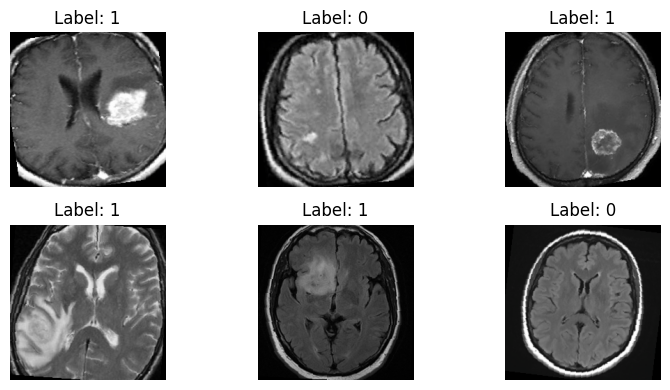

In [ ]:
# Visual confirmation
import matplotlib.pyplot as plt
import numpy as np

def denorm(img):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img = img.transpose(1,2,0)
    img = (img * std) + mean
    return np.clip(img, 0, 1)

plt.figure(figsize=(8,4))
for i in range(6):
    img = x[i].cpu().numpy()
    plt.subplot(2,3,i+1)
    plt.imshow(denorm(img))
    plt.title(f"Label: {int(y[i])}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# confirm there is no overlap between splits
import hashlib

def hash_file(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def get_hashes(split):
    root = os.path.join(SPLIT_DIR, split)
    return set(
        hash_file(os.path.join(root, cls, f))
        for cls in ["no","yes"]
        for f in os.listdir(os.path.join(root, cls))
    )

train_h = get_hashes("train")
val_h   = get_hashes("val")
test_h  = get_hashes("test")

print("Train ∩ Val:", len(train_h & val_h))
print("Train ∩ Test:", len(train_h & test_h))
print("Val ∩ Test:", len(val_h & test_h))


Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0


In [ ]:
# Confirm splits load correctly + class mapping matches
from collections import Counter

print("class_to_idx:", train_ds.class_to_idx)  # should be {'no': 0, 'yes': 1}

print("Train counts:", Counter(train_ds.targets))
print("Val counts  :", Counter(val_ds.targets))
print("Test counts :", Counter(test_ds.targets))


class_to_idx: {'no': 0, 'yes': 1}
Train counts: Counter({1: 92, 0: 53})
Val counts  : Counter({1: 19, 0: 11})
Test counts : Counter({1: 21, 0: 13})


In [ ]:
# Confirm one batch has the right shape/dtype/labels
import torch

x, y = next(iter(train_loader))

print("x shape:", x.shape)         # [B, 3, 224, 224]
print("x dtype:", x.dtype)         # torch.float32
print("y shape:", y.shape)         # [B]
print("y dtype:", y.dtype)         # torch.int64 (usually)
print("unique labels in batch:", torch.unique(y))


x shape: torch.Size([32, 3, 224, 224])
x dtype: torch.float32
y shape: torch.Size([32])
y dtype: torch.int64
unique labels in batch: tensor([0, 1])


In [ ]:
# Confirm RGB is enforced (no RGBA / grayscale sneaking in)
print("channels:", x.shape[1])
assert x.shape[1] == 3, "Not RGB! Check convert('RGB') is in your transforms."
print(" RGB confirmed (3 channels).")


channels: 3
 RGB confirmed (3 channels).


In [ ]:
# Confirm normalization actually happened
print("min/max/mean:", x.min().item(), x.max().item(), x.mean().item())


min/max/mean: -2.1179039478302 2.640000104904175 -0.5645376443862915


In [ ]:
# Confirm shuffling behaves correctly
# Train: should differ (shuffle=True)
x1, y1 = next(iter(train_loader))
x2, y2 = next(iter(train_loader))
print("Train first-batch labels equal?", torch.equal(y1, y2))  # usually False (not guaranteed, but often)

# Val: should be consistent (shuffle=False)
v1x, v1y = next(iter(val_loader))
v2x, v2y = next(iter(val_loader))
print("Val first-batch labels equal?", torch.equal(v1y, v2y))  # should be True


Train first-batch labels equal? False
Val first-batch labels equal? True


## 5. Model Design
Five models are compared: two CNNs trained from scratch, then EfficientNet-B0 with transfer learning, ending with a hyperparameter-tuned version.
All models are trained on the training set, selected on the validation set, and evaluated once on the held-out test set.

### 5.1 Model 1: Scratch CNN (4 conv blocks)

In [ ]:
# Step 1 — Define a CNN from scratch (PyTorch)

import torch
import torch.nn as nn
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

class ScratchCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            # 224x224 -> 112x112
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # 112x112 -> 56x56
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # 56x56 -> 28x28
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # 28x28 -> 14x14
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # global pool -> 1x1
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = ScratchCNN(num_classes=2).to(device)
print(model)


Using device: cpu
ScratchCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-0

In [ ]:
# Step 2 — Define loss + optimizer (with class weights)
# Data is imbalanced (more “yes” than “no”), so use class-weighted loss based on train split only.

from collections import Counter

# train_ds.targets are integer class ids in ImageFolder
counts = Counter(train_ds.targets)
no_idx  = train_ds.class_to_idx["no"]
yes_idx = train_ds.class_to_idx["yes"]

count_no  = counts[no_idx]
count_yes = counts[yes_idx]

# weights ~ inverse frequency
class_counts = torch.tensor([count_no, count_yes], dtype=torch.float)
weights = class_counts.sum() / class_counts
weights = (weights / weights.sum()).to(device)

print("Train counts [no, yes]:", [count_no, count_yes])
print("Class weights [no, yes]:", weights.detach().cpu().numpy())

criterion = nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)


Train counts [no, yes]: [53, 92]
Class weights [no, yes]: [0.63448274 0.36551723]


In [ ]:
# Step 3 — Training loop (stores history + saves best model)
# This trains on train, validates on val, saves best model by val accuracy, and stores history for learning curves.

def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        if is_train:
            optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)

        if is_train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total


epochs = 20
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_acc = 0.0
best_path = "brain_mri_binary/best_scratch_cnn.pt"

for epoch in range(1, epochs + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer=optimizer)
    val_loss, val_acc     = run_epoch(model, val_loader,   criterion, optimizer=None)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/{epochs} | "
          f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_path)

print("\nBest val acc:", best_val_acc)
print("Saved best model to:", best_path)



Epoch 01/20 | train loss 0.6688 acc 0.5931 | val loss 0.6614 acc 0.6333
Epoch 02/20 | train loss 0.5411 acc 0.7448 | val loss 0.6434 acc 0.7000
Epoch 03/20 | train loss 0.5488 acc 0.7310 | val loss 0.6997 acc 0.7000
Epoch 04/20 | train loss 0.5151 acc 0.7793 | val loss 0.6270 acc 0.6333
Epoch 05/20 | train loss 0.4902 acc 0.7586 | val loss 0.6879 acc 0.7000
Epoch 06/20 | train loss 0.5019 acc 0.7931 | val loss 0.6824 acc 0.7000
Epoch 07/20 | train loss 0.5382 acc 0.7931 | val loss 0.9092 acc 0.6333
Epoch 08/20 | train loss 0.5157 acc 0.7586 | val loss 0.6295 acc 0.7333
Epoch 09/20 | train loss 0.4586 acc 0.7931 | val loss 0.9214 acc 0.5000
Epoch 10/20 | train loss 0.4742 acc 0.7724 | val loss 0.7814 acc 0.6000
Epoch 11/20 | train loss 0.4598 acc 0.8000 | val loss 0.6266 acc 0.6000
Epoch 12/20 | train loss 0.4486 acc 0.8207 | val loss 0.8290 acc 0.6333
Epoch 13/20 | train loss 0.4890 acc 0.8000 | val loss 0.6484 acc 0.7667
Epoch 14/20 | train loss 0.4271 acc 0.8276 | val loss 1.1964 acc

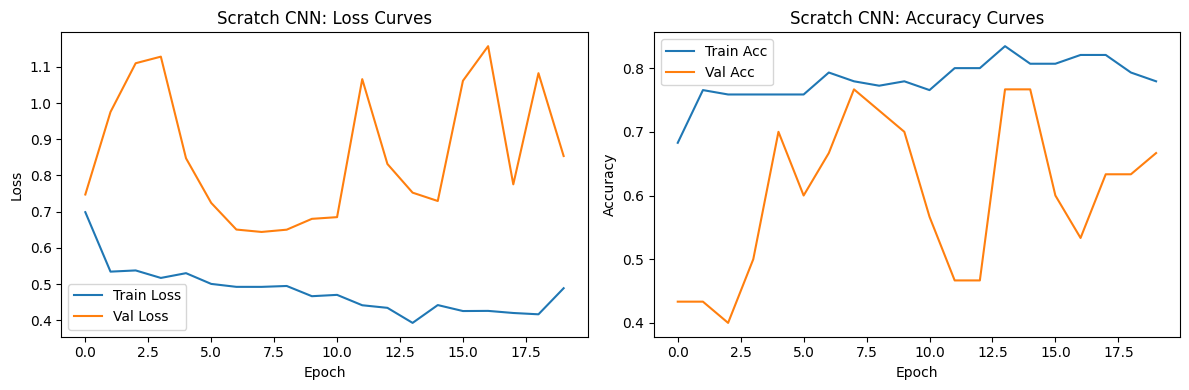

In [ ]:
# Step 4 — Plot learning curves (Loss + Accuracy)
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Scratch CNN: Loss Curves")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_acc"], label="Train Acc")
plt.plot(history["val_acc"], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Scratch CNN: Accuracy Curves")
plt.legend()

plt.tight_layout()
plt.show()


Test class_to_idx: {'no': 0, 'yes': 1}

Confusion Matrix:
 [[ 3 10]
 [ 1 20]]
TP=20, FP=10, TN=3, FN=1
TPR (Recall/Sensitivity): 0.9524
TNR (Specificity):        0.2308
Accuracy:                 0.6765
Precision:                0.6667
F1:                       0.7843
ROC-AUC:                  0.7289

Classification Report:
               precision    recall  f1-score   support

          no     0.7500    0.2308    0.3529        13
         yes     0.6667    0.9524    0.7843        21

    accuracy                         0.6765        34
   macro avg     0.7083    0.5916    0.5686        34
weighted avg     0.6985    0.6765    0.6194        34



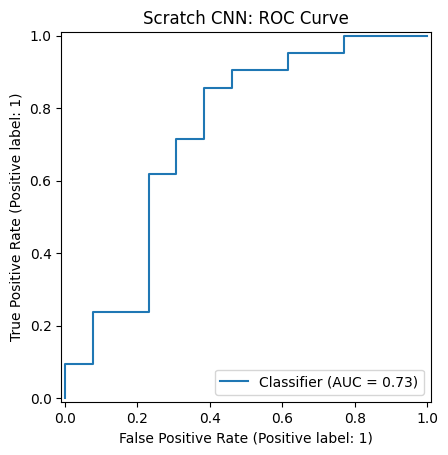

In [ ]:
# Step 5 — Test evaluation (Confusion matrix + TPR/TNR + Precision/F1/Accuracy + ROC-AUC + ROC curve)
import numpy as np
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay
)

# Load best model checkpoint
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

all_true, all_pred, all_prob = [], [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        logits = model(x)

        prob_yes = torch.softmax(logits, dim=1)[:, 1]  # P(yes)
        pred = logits.argmax(dim=1)

        all_true.extend(y.numpy())
        all_pred.extend(pred.cpu().numpy())
        all_prob.extend(prob_yes.cpu().numpy())

all_true = np.array(all_true)
all_pred = np.array(all_pred)
all_prob = np.array(all_prob)

# Confusion matrix
cm = confusion_matrix(all_true, all_pred)
TN, FP, FN, TP = cm.ravel()

TPR = TP / (TP + FN) if (TP + FN) else 0.0  # Sensitivity/Recall
TNR = TN / (TN + FP) if (TN + FP) else 0.0  # Specificity

acc  = accuracy_score(all_true, all_pred)
prec = precision_score(all_true, all_pred, zero_division=0)
rec  = recall_score(all_true, all_pred, zero_division=0)
f1   = f1_score(all_true, all_pred, zero_division=0)
auc  = roc_auc_score(all_true, all_prob)

idx_to_class = {v:k for k,v in test_ds.class_to_idx.items()}
target_names = [idx_to_class[i] for i in sorted(idx_to_class)]

print("Test class_to_idx:", test_ds.class_to_idx)
print("\nConfusion Matrix:\n", cm)
print(f"TP={TP}, FP={FP}, TN={TN}, FN={FN}")
print(f"TPR (Recall/Sensitivity): {TPR:.4f}")
print(f"TNR (Specificity):        {TNR:.4f}")
print(f"Accuracy:                 {acc:.4f}")
print(f"Precision:                {prec:.4f}")
print(f"F1:                       {f1:.4f}")
print(f"ROC-AUC:                  {auc:.4f}")

print("\nClassification Report:\n",
      classification_report(all_true, all_pred, target_names=target_names, digits=4))

RocCurveDisplay.from_predictions(all_true, all_prob)
plt.title("Scratch CNN: ROC Curve")
plt.show()


### 5.2 Model 2: Smaller Scratch CNN (3 conv blocks + early stopping)

In [ ]:
# ==========================================
# Scratch CNN (smaller variant) — 3 conv blocks
# Less capacity = less overfitting on small data
# Includes: class weights + AdamW + ReduceLROnPlateau + Early Stopping
# ==========================================
import torch
import torch.nn as nn
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ----------------------------
# 1) Smaller CNN: 3 conv blocks
# ----------------------------
class ScratchCNN_Small(nn.Module):
    def __init__(self, num_classes=2, dropout=0.5, base_channels=16):
        super().__init__()
        c1 = base_channels       # 16
        c2 = base_channels * 2   # 32
        c3 = base_channels * 4   # 64

        self.features = nn.Sequential(
            # 224 -> 112
            nn.Conv2d(3, c1, 3, padding=1),
            nn.BatchNorm2d(c1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # 112 -> 56
            nn.Conv2d(c1, c2, 3, padding=1),
            nn.BatchNorm2d(c2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # 56 -> 28
            nn.Conv2d(c2, c3, 3, padding=1),
            nn.BatchNorm2d(c3),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # global pool -> 1x1
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(c3, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = ScratchCNN_Small(num_classes=2, dropout=0.5, base_channels=16).to(device)
print(model)

# ----------------------------
# 2) Class-weighted loss (train split only)
# ----------------------------
counts = Counter(train_ds.targets)
no_idx  = train_ds.class_to_idx["no"]
yes_idx = train_ds.class_to_idx["yes"]

count_no  = counts[no_idx]
count_yes = counts[yes_idx]

class_counts = torch.tensor([count_no, count_yes], dtype=torch.float)
weights = class_counts.sum() / class_counts
weights = (weights / weights.sum()).to(device)

print("Train counts [no, yes]:", [count_no, count_yes])
print("Class weights [no, yes]:", weights.detach().cpu().numpy())

criterion = nn.CrossEntropyLoss(weight=weights)

# ----------------------------
# 3) Optimizer + scheduler
# ----------------------------
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=5e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

# ----------------------------
# 4) Epoch runner (with grad clipping)
# ----------------------------
def run_epoch(model, loader, criterion, optimizer=None, grad_clip=1.0):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        logits = model(x)
        loss = criterion(logits, y)

        if is_train:
            loss.backward()
            if grad_clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total

# ----------------------------
# 5) Training loop + Early stopping on val loss
# ----------------------------
epochs = 30
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_loss = float("inf")
best_val_acc = 0.0
best_path = "brain_mri_binary/best_scratch_cnn_small.pt"

patience = 4
patience_left = patience
min_delta = 1e-4

for epoch in range(1, epochs + 1):
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer=optimizer, grad_clip=1.0)
    val_loss, val_acc     = run_epoch(model, val_loader,   criterion, optimizer=None)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    scheduler.step(val_loss)
    lr_now = optimizer.param_groups[0]["lr"]

    print(f"Epoch {epoch:02d}/{epochs} | "
          f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f} | lr {lr_now:.2e}")

    if val_loss < (best_val_loss - min_delta):
        best_val_loss = val_loss
        best_val_acc = val_acc
        patience_left = patience
        torch.save(model.state_dict(), best_path)
    else:
        patience_left -= 1
        if patience_left == 0:
            print(f"\nEarly stopping triggered at epoch {epoch}.")
            break

print("\nBest checkpoint saved to:", best_path)
print("Best val loss:", best_val_loss)
print("Val acc at best loss:", best_val_acc)


Using device: cpu
ScratchCNN_Small(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1,

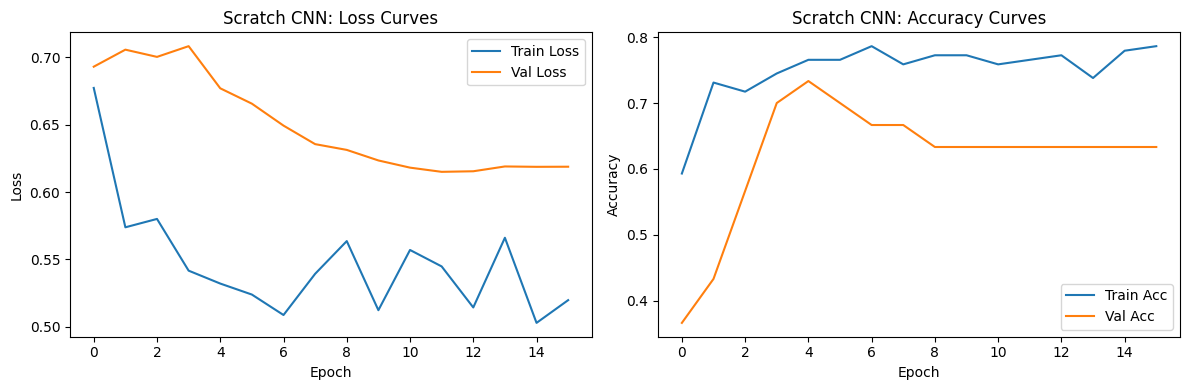

In [ ]:
# Step 4 — Plot learning curves (Loss + Accuracy)
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Scratch CNN: Loss Curves")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_acc"], label="Train Acc")
plt.plot(history["val_acc"], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Scratch CNN: Accuracy Curves")
plt.legend()

plt.tight_layout()
plt.show()


Test class_to_idx: {'no': 0, 'yes': 1}

Confusion Matrix:
 [[ 6  7]
 [ 3 18]]
TP=18, FP=7, TN=6, FN=3
TPR (Recall/Sensitivity): 0.8571
TNR (Specificity):        0.4615
Accuracy:                 0.7059
Precision:                0.7200
F1:                       0.7826
ROC-AUC:                  0.6557

Classification Report:
               precision    recall  f1-score   support

          no     0.6667    0.4615    0.5455        13
         yes     0.7200    0.8571    0.7826        21

    accuracy                         0.7059        34
   macro avg     0.6933    0.6593    0.6640        34
weighted avg     0.6996    0.7059    0.6919        34



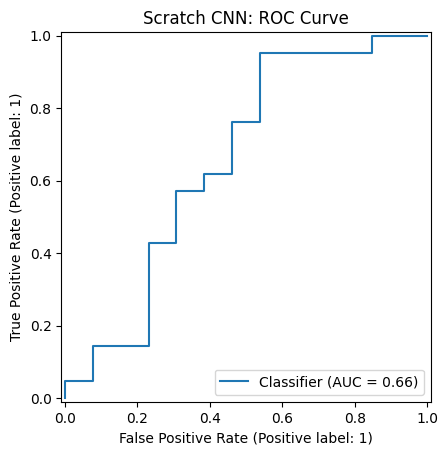

In [ ]:
# Step 5 — Test evaluation (Confusion matrix + TPR/TNR + Precision/F1/Accuracy + ROC-AUC + ROC curve)
import numpy as np
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay
)

# Load best model checkpoint
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

all_true, all_pred, all_prob = [], [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        logits = model(x)

        prob_yes = torch.softmax(logits, dim=1)[:, 1]  # P(yes)
        pred = logits.argmax(dim=1)

        all_true.extend(y.numpy())
        all_pred.extend(pred.cpu().numpy())
        all_prob.extend(prob_yes.cpu().numpy())

all_true = np.array(all_true)
all_pred = np.array(all_pred)
all_prob = np.array(all_prob)

# Confusion matrix
cm = confusion_matrix(all_true, all_pred)
TN, FP, FN, TP = cm.ravel()

TPR = TP / (TP + FN) if (TP + FN) else 0.0  # Sensitivity/Recall
TNR = TN / (TN + FP) if (TN + FP) else 0.0  # Specificity

acc  = accuracy_score(all_true, all_pred)
prec = precision_score(all_true, all_pred, zero_division=0)
rec  = recall_score(all_true, all_pred, zero_division=0)
f1   = f1_score(all_true, all_pred, zero_division=0)
auc  = roc_auc_score(all_true, all_prob)

idx_to_class = {v:k for k,v in test_ds.class_to_idx.items()}
target_names = [idx_to_class[i] for i in sorted(idx_to_class)]

print("Test class_to_idx:", test_ds.class_to_idx)
print("\nConfusion Matrix:\n", cm)
print(f"TP={TP}, FP={FP}, TN={TN}, FN={FN}")
print(f"TPR (Recall/Sensitivity): {TPR:.4f}")
print(f"TNR (Specificity):        {TNR:.4f}")
print(f"Accuracy:                 {acc:.4f}")
print(f"Precision:                {prec:.4f}")
print(f"F1:                       {f1:.4f}")
print(f"ROC-AUC:                  {auc:.4f}")

print("\nClassification Report:\n",
      classification_report(all_true, all_pred, target_names=target_names, digits=4))

RocCurveDisplay.from_predictions(all_true, all_prob)
plt.title("Scratch CNN: ROC Curve")
plt.show()


### 5.3 Model 3: EfficientNet-B0 (Transfer Learning, ImageNet Preprocessing)



In [ ]:
# Step 1 — EfficientNet-B0 model (pretrained) + replace head
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained EfficientNet-B0
weights_eff = models.EfficientNet_B0_Weights.DEFAULT
model_eff = models.efficientnet_b0(weights=weights_eff)

# Replace classifier for 2 classes
in_features = model_eff.classifier[1].in_features
model_eff.classifier[1] = nn.Linear(in_features, 2)

model_eff = model_eff.to(device)
print(model_eff.classifier)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 147MB/s]

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [ ]:
# Step 2 — Loss + optimizer (with class weights from TRAIN split)
from collections import Counter

counts = Counter(train_ds.targets)
no_idx  = train_ds.class_to_idx["no"]
yes_idx = train_ds.class_to_idx["yes"]

count_no  = counts[no_idx]
count_yes = counts[yes_idx]

class_counts = torch.tensor([count_no, count_yes], dtype=torch.float)
weights = class_counts.sum() / class_counts
weights = (weights / weights.sum()).to(device)

print("Train counts [no, yes]:", [count_no, count_yes])
print("Class weights [no, yes]:", weights.detach().cpu().numpy())

criterion_eff = nn.CrossEntropyLoss(weight=weights)


Train counts [no, yes]: [53, 92]
Class weights [no, yes]: [0.63448274 0.36551723]


In [ ]:
# Step 3 — Helper: epoch runner (same as before)
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        if is_train:
            optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)

        if is_train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total


In [ ]:
# Step 4 — Phase 1: Freeze backbone, train classifier head only (history + save best)
# Freeze the feature extractor
for p in model_eff.features.parameters():
    p.requires_grad = False

# Optimizer only for classifier head
optimizer_eff = torch.optim.AdamW(model_eff.classifier.parameters(), lr=1e-3, weight_decay=1e-4)

epochs_phase1 = 3
history_eff = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_acc_eff = 0.0
best_path_eff = "brain_mri_binary/best_effnetb0.pt"

for epoch in range(1, epochs_phase1 + 1):
    train_loss, train_acc = run_epoch(model_eff, train_loader, criterion_eff, optimizer=optimizer_eff)
    val_loss, val_acc     = run_epoch(model_eff, val_loader,   criterion_eff, optimizer=None)

    history_eff["train_loss"].append(train_loss)
    history_eff["val_loss"].append(val_loss)
    history_eff["train_acc"].append(train_acc)
    history_eff["val_acc"].append(val_acc)

    print(f"[Phase1 Frozen] Epoch {epoch}/{epochs_phase1} | "
          f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    if val_acc > best_val_acc_eff:
        best_val_acc_eff = val_acc
        torch.save(model_eff.state_dict(), best_path_eff)

print("\nBest val acc after Phase 1:", best_val_acc_eff)
print("Saved best EfficientNet-B0 to:", best_path_eff)


[Phase1 Frozen] Epoch 1/3 | train loss 0.5914 acc 0.7862 | val loss 0.6974 acc 0.5333
[Phase1 Frozen] Epoch 2/3 | train loss 0.5001 acc 0.8690 | val loss 0.6620 acc 0.5667
[Phase1 Frozen] Epoch 3/3 | train loss 0.4594 acc 0.8483 | val loss 0.6554 acc 0.5667

Best val acc after Phase 1: 0.5666666666666667
Saved best EfficientNet-B0 to: brain_mri_binary/best_effnetb0.pt


In [ ]:
# Step 5 — Phase 2: Unfreeze + fine-tune (continue history + save best)
# Unfreeze backbone for fine-tuning
for p in model_eff.features.parameters():
    p.requires_grad = True

# Lower LR for fine-tuning
optimizer_eff = torch.optim.AdamW(model_eff.parameters(), lr=1e-4, weight_decay=1e-4)

epochs_phase2 = 5

for epoch in range(1, epochs_phase2 + 1):
    train_loss, train_acc = run_epoch(model_eff, train_loader, criterion_eff, optimizer=optimizer_eff)
    val_loss, val_acc     = run_epoch(model_eff, val_loader,   criterion_eff, optimizer=None)

    history_eff["train_loss"].append(train_loss)
    history_eff["val_loss"].append(val_loss)
    history_eff["train_acc"].append(train_acc)
    history_eff["val_acc"].append(val_acc)

    print(f"[Phase2 Finetune] Epoch {epoch}/{epochs_phase2} | "
          f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    if val_acc > best_val_acc_eff:
        best_val_acc_eff = val_acc
        torch.save(model_eff.state_dict(), best_path_eff)

print("\nBest val acc overall:", best_val_acc_eff)
print("Saved best EfficientNet-B0 to:", best_path_eff)


[Phase2 Finetune] Epoch 1/5 | train loss 0.3981 acc 0.8759 | val loss 0.6357 acc 0.6667
[Phase2 Finetune] Epoch 2/5 | train loss 0.3427 acc 0.8828 | val loss 0.5884 acc 0.6667
[Phase2 Finetune] Epoch 3/5 | train loss 0.2511 acc 0.9241 | val loss 0.5212 acc 0.7333
[Phase2 Finetune] Epoch 4/5 | train loss 0.1973 acc 0.9448 | val loss 0.4999 acc 0.7333
[Phase2 Finetune] Epoch 5/5 | train loss 0.1590 acc 0.9793 | val loss 0.4752 acc 0.7667

Best val acc overall: 0.7666666666666667
Saved best EfficientNet-B0 to: brain_mri_binary/best_effnetb0.pt


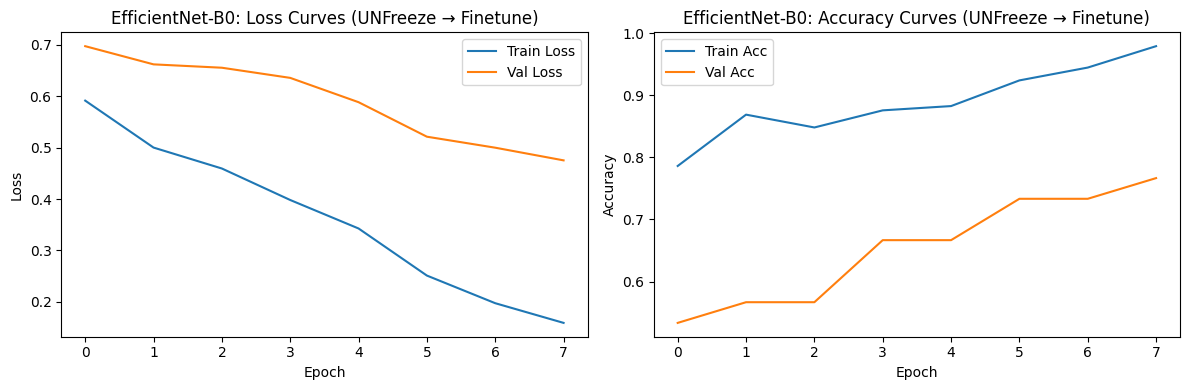

In [ ]:
# Step 6 — Plot learning curves (Loss + Accuracy)
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history_eff["train_loss"], label="Train Loss")
plt.plot(history_eff["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B0: Loss Curves (Unfreeze → Finetune)")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_eff["train_acc"], label="Train Acc")
plt.plot(history_eff["val_acc"], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNet-B0: Accuracy Curves (Unfreeze → Finetune)")
plt.legend()

plt.tight_layout()
plt.show()


Test class_to_idx: {'no': 0, 'yes': 1}

Confusion Matrix:
 [[12  1]
 [ 3 18]]
TP=18, FP=1, TN=12, FN=3
TPR (Recall/Sensitivity): 0.8571
TNR (Specificity):        0.9231
Accuracy:                 0.8824
Precision:                0.9474
F1:                       0.9000
ROC-AUC:                  0.9744

Classification Report:
               precision    recall  f1-score   support

          no     0.8000    0.9231    0.8571        13
         yes     0.9474    0.8571    0.9000        21

    accuracy                         0.8824        34
   macro avg     0.8737    0.8901    0.8786        34
weighted avg     0.8910    0.8824    0.8836        34



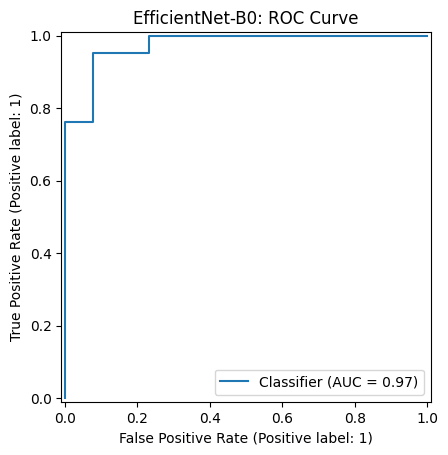

In [ ]:
# Step 7 — Test evaluation (Confusion Matrix + TPR/TNR + metrics + ROC-AUC + ROC curve)
import numpy as np
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay
)

# Load best checkpoint
model_eff.load_state_dict(torch.load(best_path_eff, map_location=device))
model_eff.eval()

all_true, all_pred, all_prob = [], [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        logits = model_eff(x)

        prob_yes = torch.softmax(logits, dim=1)[:, 1]  # P(yes)
        pred = logits.argmax(dim=1)

        all_true.extend(y.numpy())
        all_pred.extend(pred.cpu().numpy())
        all_prob.extend(prob_yes.cpu().numpy())

all_true = np.array(all_true)
all_pred = np.array(all_pred)
all_prob = np.array(all_prob)

cm = confusion_matrix(all_true, all_pred)
TN, FP, FN, TP = cm.ravel()

TPR = TP / (TP + FN) if (TP + FN) else 0.0
TNR = TN / (TN + FP) if (TN + FP) else 0.0

acc  = accuracy_score(all_true, all_pred)
prec = precision_score(all_true, all_pred, zero_division=0)
rec  = recall_score(all_true, all_pred, zero_division=0)
f1   = f1_score(all_true, all_pred, zero_division=0)
auc  = roc_auc_score(all_true, all_prob)

idx_to_class = {v:k for k,v in test_ds.class_to_idx.items()}
target_names = [idx_to_class[i] for i in sorted(idx_to_class)]

print("Test class_to_idx:", test_ds.class_to_idx)
print("\nConfusion Matrix:\n", cm)
print(f"TP={TP}, FP={FP}, TN={TN}, FN={FN}")
print(f"TPR (Recall/Sensitivity): {TPR:.4f}")
print(f"TNR (Specificity):        {TNR:.4f}")
print(f"Accuracy:                 {acc:.4f}")
print(f"Precision:                {prec:.4f}")
print(f"F1:                       {f1:.4f}")
print(f"ROC-AUC:                  {auc:.4f}")

print("\nClassification Report:\n",
      classification_report(all_true, all_pred, target_names=target_names, digits=4))

RocCurveDisplay.from_predictions(all_true, all_prob)
plt.title("EfficientNet-B0: ROC Curve")
plt.show()


### 5.4 Model 4: EfficientNet-B0 (Official EfficientNet Preprocessing)


In [ ]:
# Used ImageNet mean/std + 224 crop above
# Scratch CNN → used transforms (ImageNet mean/std + augmentation)
# EfficientNet-B0 → switch transforms BEFORE training (weights_eff.transforms())
# Do not reuse scratch CNN loaders for EfficientNet
# Do not mix transforms across models
# Do not retrain scratch CNN after switching
# Each model gets its own preprocessing pipeline.

# Step A — Get EfficientNet’s pretrained transforms
from torchvision import models, datasets
from torch.utils.data import DataLoader
import torch
import os

weights_eff = models.EfficientNet_B0_Weights.DEFAULT
eff_tfms = weights_eff.transforms()


In [ ]:
# Step B — Rebuild datasets using EfficientNet transforms
SPLIT_DIR = "brain_mri_binary/splits"
train_dir = os.path.join(SPLIT_DIR, "train")
val_dir   = os.path.join(SPLIT_DIR, "val")
test_dir  = os.path.join(SPLIT_DIR, "test")

train_ds_eff = datasets.ImageFolder(train_dir, transform=eff_tfms)
val_ds_eff   = datasets.ImageFolder(val_dir,   transform=eff_tfms)
test_ds_eff  = datasets.ImageFolder(test_dir,  transform=eff_tfms)

print("EfficientNet class_to_idx:", train_ds_eff.class_to_idx)


EfficientNet class_to_idx: {'no': 0, 'yes': 1}


In [ ]:
# Step C — Rebuild dataloaders
pin = torch.cuda.is_available()

train_loader_eff = DataLoader(
    train_ds_eff, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=pin
)

val_loader_eff = DataLoader(
    val_ds_eff, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=pin
)

test_loader_eff = DataLoader(
    test_ds_eff, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=pin
)


In [ ]:
# Step D — Sanity check
x, y = next(iter(train_loader_eff))
print("EfficientNet batch shape:", x.shape)   # [B, 3, 224, 224]
print("dtype:", x.dtype)
print("label set:", torch.unique(y))
print("pixel min/max:", x.min().item(), x.max().item())

# Expected:
   # shape → [32, 3, 224, 224]
   # dtype → float32
   # pixel range → roughly [-2.5, +2.5] (after normalization)

EfficientNet batch shape: torch.Size([32, 3, 224, 224])
dtype: torch.float32
label set: tensor([0, 1])
pixel min/max: -2.1179039478302 2.640000104904175


In [ ]:
# Step 1 — Define EfficientNet-B0 + replace classifier head (2 classes)
import torch
import torch.nn as nn
from torchvision import models


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

weights_eff = models.EfficientNet_B0_Weights.DEFAULT

model_eff = models.efficientnet_b0(weights=weights_eff)

# Replace classifier head
in_features = model_eff.classifier[1].in_features
model_eff.classifier[1] = nn.Linear(in_features, 2)

model_eff = model_eff.to(device)

print("Classifier head:", model_eff.classifier)

Using device: cpu
Classifier head: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [ ]:
# Step 2 — Define loss + optimizer (class weights from train_ds_eff)
from collections import Counter

counts = Counter(train_ds_eff.targets)
no_idx  = train_ds_eff.class_to_idx["no"]
yes_idx = train_ds_eff.class_to_idx["yes"]

count_no  = counts[no_idx]
count_yes = counts[yes_idx]

class_counts = torch.tensor([count_no, count_yes], dtype=torch.float)
class_weights = class_counts.sum() / class_counts
class_weights = (class_weights / class_weights.sum()).to(device)

print("Train counts [no, yes]:", [count_no, count_yes])
print("Class weights [no, yes]:", class_weights.detach().cpu().numpy())

criterion_eff = nn.CrossEntropyLoss(weight=class_weights)

Train counts [no, yes]: [53, 92]
Class weights [no, yes]: [0.63448274 0.36551723]


In [ ]:
# Step 3 — Training helper (stores loss/acc per epoch)
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        if is_train:
            optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)

        if is_train:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total

In [ ]:
# Step 4 — Phase 1: Freeze backbone, train head only (save best)
# Freeze feature extractor
for p in model_eff.features.parameters():
    p.requires_grad = False

optimizer_eff = torch.optim.AdamW(model_eff.classifier.parameters(), lr=1e-3, weight_decay=1e-4)

epochs_phase1 = 3
history_eff = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

best_val_acc_eff = 0.0
best_path_eff = "brain_mri_binary/best_effnetb0.pt"

for epoch in range(1, epochs_phase1 + 1):
    train_loss, train_acc = run_epoch(model_eff, train_loader_eff, criterion_eff, optimizer=optimizer_eff)
    val_loss, val_acc     = run_epoch(model_eff, val_loader_eff,   criterion_eff, optimizer=None)

    history_eff["train_loss"].append(train_loss)
    history_eff["val_loss"].append(val_loss)
    history_eff["train_acc"].append(train_acc)
    history_eff["val_acc"].append(val_acc)

    print(f"[Phase1 Frozen] Epoch {epoch}/{epochs_phase1} | "
          f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    if val_acc > best_val_acc_eff:
        best_val_acc_eff = val_acc
        torch.save(model_eff.state_dict(), best_path_eff)

print("\nBest val acc after Phase 1:", best_val_acc_eff)
print("Saved best EfficientNet to:", best_path_eff)

[Phase1 Frozen] Epoch 1/3 | train loss 0.7038 acc 0.5517 | val loss 0.6971 acc 0.5000
[Phase1 Frozen] Epoch 2/3 | train loss 0.5851 acc 0.7862 | val loss 0.6549 acc 0.6333
[Phase1 Frozen] Epoch 3/3 | train loss 0.5108 acc 0.8276 | val loss 0.5973 acc 0.6333

Best val acc after Phase 1: 0.6333333333333333
Saved best EfficientNet to: brain_mri_binary/best_effnetb0.pt


In [ ]:
# Step 5 — Phase 2: Unfreeze + fine-tune (continue history, save best)
# Unfreeze backbone
for p in model_eff.features.parameters():
    p.requires_grad = True

optimizer_eff = torch.optim.AdamW(model_eff.parameters(), lr=1e-4, weight_decay=1e-4)

epochs_phase2 = 5

for epoch in range(1, epochs_phase2 + 1):
    train_loss, train_acc = run_epoch(model_eff, train_loader_eff, criterion_eff, optimizer=optimizer_eff)
    val_loss, val_acc     = run_epoch(model_eff, val_loader_eff,   criterion_eff, optimizer=None)

    history_eff["train_loss"].append(train_loss)
    history_eff["val_loss"].append(val_loss)
    history_eff["train_acc"].append(train_acc)
    history_eff["val_acc"].append(val_acc)

    print(f"[Phase2 Finetune] Epoch {epoch}/{epochs_phase2} | "
          f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    if val_acc > best_val_acc_eff:
        best_val_acc_eff = val_acc
        torch.save(model_eff.state_dict(), best_path_eff)

print("\nBest val acc overall:", best_val_acc_eff)
print("Saved best EfficientNet to:", best_path_eff)

[Phase2 Finetune] Epoch 1/5 | train loss 0.4567 acc 0.8828 | val loss 0.5351 acc 0.7000
[Phase2 Finetune] Epoch 2/5 | train loss 0.3182 acc 0.9310 | val loss 0.5125 acc 0.7333
[Phase2 Finetune] Epoch 3/5 | train loss 0.2320 acc 0.9724 | val loss 0.5059 acc 0.7333
[Phase2 Finetune] Epoch 4/5 | train loss 0.1768 acc 0.9793 | val loss 0.4959 acc 0.7333
[Phase2 Finetune] Epoch 5/5 | train loss 0.1502 acc 0.9793 | val loss 0.4748 acc 0.8000

Best val acc overall: 0.8
Saved best EfficientNet to: brain_mri_binary/best_effnetb0.pt


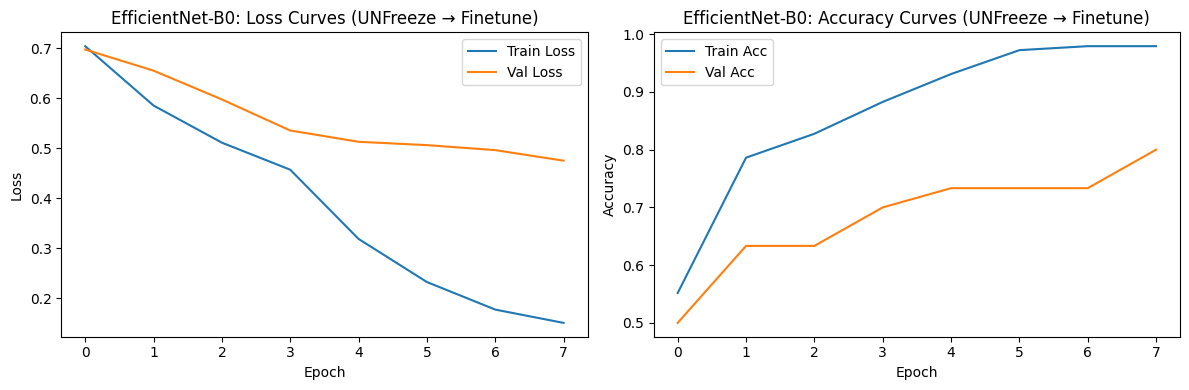

In [ ]:
# Step 6 — Plot learning curves (Loss + Accuracy)
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history_eff["train_loss"], label="Train Loss")
plt.plot(history_eff["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B0: Loss Curves (UnFreeze → Finetune)")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_eff["train_acc"], label="Train Acc")
plt.plot(history_eff["val_acc"], label="Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNet-B0: Accuracy Curves (UnFreeze → Finetune)")
plt.legend()

plt.tight_layout()
plt.show()

Test class_to_idx: {'no': 0, 'yes': 1}

Confusion Matrix:
 [[12  1]
 [ 2 19]]
TP=19, FP=1, TN=12, FN=2
TPR (Recall/Sensitivity): 0.9048
TNR (Specificity):        0.9231
Accuracy:                 0.9118
Precision:                0.9500
F1:                       0.9268
ROC-AUC:                  0.9780

Classification Report:
               precision    recall  f1-score   support

          no     0.8571    0.9231    0.8889        13
         yes     0.9500    0.9048    0.9268        21

    accuracy                         0.9118        34
   macro avg     0.9036    0.9139    0.9079        34
weighted avg     0.9145    0.9118    0.9123        34



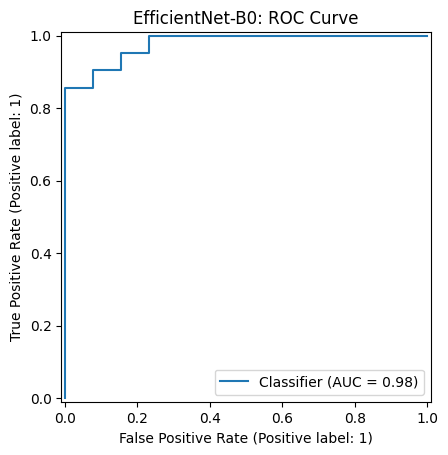

In [ ]:
# Step 7 — Test evaluation (labels from test_ds_eff)

# This uses test_loader_eff and class labels from test_ds_eff.class_to_idx.

import numpy as np
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay
)

# Load best checkpoint
model_eff.load_state_dict(torch.load(best_path_eff, map_location=device))
model_eff.eval()

all_true, all_pred, all_prob = [], [], []

with torch.no_grad():
    for x, y in test_loader_eff:
        x = x.to(device)
        logits = model_eff(x)

        prob_yes = torch.softmax(logits, dim=1)[:, 1]  # P(yes)
        pred = logits.argmax(dim=1)

        all_true.extend(y.numpy())
        all_pred.extend(pred.cpu().numpy())
        all_prob.extend(prob_yes.cpu().numpy())

all_true = np.array(all_true)
all_pred = np.array(all_pred)
all_prob = np.array(all_prob)

cm = confusion_matrix(all_true, all_pred)
TN, FP, FN, TP = cm.ravel()

TPR = TP / (TP + FN) if (TP + FN) else 0.0   # sensitivity/recall
TNR = TN / (TN + FP) if (TN + FP) else 0.0   # specificity

acc  = accuracy_score(all_true, all_pred)
prec = precision_score(all_true, all_pred, zero_division=0)
rec  = recall_score(all_true, all_pred, zero_division=0)
f1   = f1_score(all_true, all_pred, zero_division=0)
auc  = roc_auc_score(all_true, all_prob)

idx_to_class = {v:k for k,v in test_ds_eff.class_to_idx.items()}
target_names = [idx_to_class[i] for i in sorted(idx_to_class)]

print("Test class_to_idx:", test_ds_eff.class_to_idx)
print("\nConfusion Matrix:\n", cm)
print(f"TP={TP}, FP={FP}, TN={TN}, FN={FN}")
print(f"TPR (Recall/Sensitivity): {TPR:.4f}")
print(f"TNR (Specificity):        {TNR:.4f}")
print(f"Accuracy:                 {acc:.4f}")
print(f"Precision:                {prec:.4f}")
print(f"F1:                       {f1:.4f}")
print(f"ROC-AUC:                  {auc:.4f}")

print("\nClassification Report:\n",
      classification_report(all_true, all_pred, target_names=target_names, digits=4))

RocCurveDisplay.from_predictions(all_true, all_prob)
plt.title("EfficientNet-B0: ROC Curve")
plt.show()

### 5.5 Model 5: Hyperparameter-Tuned EfficientNet-B0


In [ ]:
# Step 0 — Imports + Reproducibility
import os
import time
import copy
import random
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)



Device: cpu


In [ ]:
# Step 1 — Define ImageNet transforms (EfficientNet-B0 input)
IMG_SIZE = 224

train_tfms = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

val_tfms = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])


In [ ]:
# Step 2 — Load datasets from split folders
SPLIT_ROOT = "brain_mri_binary/splits"  # change if needed

train_dir = os.path.join(SPLIT_ROOT, "train")
val_dir   = os.path.join(SPLIT_ROOT, "val")
test_dir  = os.path.join(SPLIT_ROOT, "test")

train_ds = datasets.ImageFolder(train_dir, transform=train_tfms)
val_ds   = datasets.ImageFolder(val_dir,   transform=val_tfms)
test_ds  = datasets.ImageFolder(test_dir,  transform=val_tfms)

print("class_to_idx:", train_ds.class_to_idx)  # {'no':0, 'yes':1}


class_to_idx: {'no': 0, 'yes': 1}


In [ ]:
# Step 3 — Build DataLoaders (with optional weighted sampling)
def make_weighted_sampler(train_ds):
    # weights for each sample = inverse class frequency
    targets = np.array(train_ds.targets)
    class_counts = np.bincount(targets)
    class_weights = 1.0 / class_counts
    sample_weights = class_weights[targets]
    sampler = WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(sample_weights),
        replacement=True
    )
    return sampler, class_counts

sampler, class_counts = make_weighted_sampler(train_ds)
print("Train class counts [no, yes]:", class_counts)

def make_loaders(batch_size=16, use_sampler=True, num_workers=2):
    if use_sampler:
        train_loader = DataLoader(train_ds, batch_size=batch_size, sampler=sampler,
                                  num_workers=num_workers, pin_memory=False)
    else:
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                                  num_workers=num_workers, pin_memory=False)

    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                            num_workers=num_workers, pin_memory=False)

    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=False)

    return train_loader, val_loader, test_loader



Train class counts [no, yes]: [53 92]


In [ ]:
# Step 4 — Create EfficientNet-B0 with tunable dropout + unfreezing
def build_efficientnet_b0(num_classes=2, dropout=0.3, unfreeze_blocks=1):
    """
    unfreeze_blocks:
      0 = only classifier trainable (fully frozen backbone)
      1 = unfreeze last block
      2 = unfreeze last 2 blocks
    """
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

    # Replace classifier head
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=dropout),
        nn.Linear(in_features, num_classes)
    )

    # Freeze everything
    for p in model.parameters():
        p.requires_grad = False

    # Always train classifier
    for p in model.classifier.parameters():
        p.requires_grad = True

    # Optionally unfreeze last N blocks of features
    if unfreeze_blocks > 0:
        # model.features is a Sequential of blocks
        blocks = list(model.features.children())
        # unfreeze last N blocks
        for b in blocks[-unfreeze_blocks:]:
            for p in b.parameters():
                p.requires_grad = True

    return model


In [ ]:
# Step 5 — Training + validation (with early stopping)
from sklearn.metrics import roc_auc_score

def run_one_epoch(model, loader, criterion, optimizer=None):
    train_mode = optimizer is not None
    model.train(train_mode)

    losses = []
    y_true, y_prob = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)

        logits = model(x)
        loss = criterion(logits, y)

        if train_mode:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        losses.append(loss.item())
        probs = torch.softmax(logits, dim=1)[:, 1].detach().cpu().numpy()

        y_true.extend(y.detach().cpu().numpy())
        y_prob.extend(probs)

    avg_loss = float(np.mean(losses))
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan
    return avg_loss, auc
def train_with_early_stopping(model, train_loader, val_loader, lr=1e-4, wd=1e-4,
                              max_epochs=8, patience=2):

    model = model.to(device)

    # Only parameters that require_grad=True
    params = [p for p in model.parameters() if p.requires_grad]

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(params, lr=lr, weight_decay=wd)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=1
    )

    best_state = None
    best_val_loss = float("inf")
    best_epoch = 0
    patience_left = patience

    hist = {"train_loss": [], "val_loss": [], "train_auc": [], "val_auc": []}

    for epoch in range(1, max_epochs + 1):
        train_loss, train_auc = run_one_epoch(model, train_loader, criterion, optimizer=optimizer)
        val_loss, val_auc     = run_one_epoch(model, val_loader,   criterion, optimizer=None)

        scheduler.step(val_loss)

        hist["train_loss"].append(train_loss)
        hist["val_loss"].append(val_loss)
        hist["train_auc"].append(train_auc)
        hist["val_auc"].append(val_auc)

        print(f"Epoch {epoch:02d}/{max_epochs} | "
              f"train loss {train_loss:.4f} auc {train_auc:.4f} | "
              f"val loss {val_loss:.4f} auc {val_auc:.4f}")

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            patience_left = patience
        else:
            patience_left -= 1
            if patience_left == 0:
                break

    # Restore best
    model.load_state_dict(best_state)
    return model, best_val_loss, best_epoch, hist



In [ ]:
# Step 6 — Define a small CPU-friendly search space
search_space = {
    "batch_size": [8, 16],
    "dropout": [0.2, 0.3, 0.5],
    "lr": [1e-4, 3e-4],
    "wd": [1e-4, 5e-4],
    "unfreeze_blocks": [1, 2],   # unfreeze last 1 or last 2 blocks
}


In [ ]:
# Step 7 — Grid search loop (tracks best model)
results = []
best_overall = {"val_loss": float("inf"), "cfg": None, "model_state": None, "hist": None}

run_id = 0
for bs in search_space["batch_size"]:
    train_loader, val_loader, test_loader = make_loaders(batch_size=bs, use_sampler=True)

    for dropout in search_space["dropout"]:
        for lr in search_space["lr"]:
            for wd in search_space["wd"]:
                for unfreeze_blocks in search_space["unfreeze_blocks"]:
                    run_id += 1
                    cfg = dict(batch_size=bs, dropout=dropout, lr=lr, wd=wd, unfreeze_blocks=unfreeze_blocks)

                    print("\n" + "="*70)
                    print(f"Run {run_id} | cfg: {cfg}")

                    model = build_efficientnet_b0(
                        num_classes=2,
                        dropout=dropout,
                        unfreeze_blocks=unfreeze_blocks
                    )

                    model, best_val_loss, best_epoch, hist = train_with_early_stopping(
                        model, train_loader, val_loader,
                        lr=lr, wd=wd,
                        max_epochs=8, patience=2
                    )

                    # Evaluate quickly on val AUC at end (from hist last value)
                    val_auc_final = hist["val_auc"][-1]

                    results.append({
                        **cfg,
                        "best_val_loss": best_val_loss,
                        "best_epoch": best_epoch,
                        "val_auc_last": val_auc_final
                    })

                    if best_val_loss < best_overall["val_loss"]:
                        best_overall["val_loss"] = best_val_loss
                        best_overall["cfg"] = cfg
                        best_overall["model_state"] = copy.deepcopy(model.state_dict())
                        best_overall["hist"] = hist

print("\nBEST CONFIG:", best_overall["cfg"])
print("BEST VAL LOSS:", best_overall["val_loss"])



Run 1 | cfg: {'batch_size': 8, 'dropout': 0.2, 'lr': 0.0001, 'wd': 0.0001, 'unfreeze_blocks': 1}
Epoch 01/8 | train loss 0.6603 auc 0.6885 | val loss 0.6183 auc 0.8708
Epoch 02/8 | train loss 0.6131 auc 0.7878 | val loss 0.6331 auc 0.8421
Epoch 03/8 | train loss 0.5481 auc 0.8903 | val loss 0.6521 auc 0.8469

Run 2 | cfg: {'batch_size': 8, 'dropout': 0.2, 'lr': 0.0001, 'wd': 0.0001, 'unfreeze_blocks': 2}
Epoch 01/8 | train loss 0.6484 auc 0.7450 | val loss 0.6503 auc 0.8182
Epoch 02/8 | train loss 0.5678 auc 0.8620 | val loss 0.5975 auc 0.8708
Epoch 03/8 | train loss 0.4708 auc 0.9257 | val loss 0.6153 auc 0.8325
Epoch 04/8 | train loss 0.4937 auc 0.8815 | val loss 0.5646 auc 0.8325
Epoch 05/8 | train loss 0.3739 auc 0.9423 | val loss 0.6100 auc 0.8230
Epoch 06/8 | train loss 0.3706 auc 0.9415 | val loss 0.5812 auc 0.8325

Run 3 | cfg: {'batch_size': 8, 'dropout': 0.2, 'lr': 0.0001, 'wd': 0.0005, 'unfreeze_blocks': 1}
Epoch 01/8 | train loss 0.6724 auc 0.6227 | val loss 0.6605 auc 0.6

In [ ]:
# Step 8 — Load best config and evaluate on TEST (accuracy, F1, ROC-AUC)
from sklearn.metrics import confusion_matrix, classification_report

def eval_on_loader(model, loader):
    model.eval()
    y_true, y_pred, y_prob = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            logits = model(x)
            probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
            preds = logits.argmax(dim=1).cpu().numpy()

            y_true.extend(y.numpy())
            y_pred.extend(preds)
            y_prob.extend(probs)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.array(y_prob)

    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan
    cm  = confusion_matrix(y_true, y_pred)
    return acc, f1, auc, cm, y_true, y_prob, y_pred

# rebuild loaders using best batch size
best_bs = best_overall["cfg"]["batch_size"]
train_loader, val_loader, test_loader = make_loaders(batch_size=best_bs, use_sampler=True)

# rebuild model and load best weights
best_cfg = best_overall["cfg"]
best_model = build_efficientnet_b0(
    num_classes=2,
    dropout=best_cfg["dropout"],
    unfreeze_blocks=best_cfg["unfreeze_blocks"]
).to(device)

best_model.load_state_dict(best_overall["model_state"])

test_acc, test_f1, test_auc, cm, y_true, y_prob, y_pred = eval_on_loader(best_model, test_loader)

print("\nTEST RESULTS")
print("Accuracy:", test_acc)
print("F1:", test_f1)
print("ROC-AUC:", test_auc)
print("Confusion Matrix:\n", cm)
print("\nClassification Report:\n", classification_report(y_true, y_pred, target_names=["no", "yes"]))



TEST RESULTS
Accuracy: 0.9411764705882353
F1: 0.9545454545454546
ROC-AUC: 0.978021978021978
Confusion Matrix:
 [[11  2]
 [ 0 21]]

Classification Report:
               precision    recall  f1-score   support

          no       1.00      0.85      0.92        13
         yes       0.91      1.00      0.95        21

    accuracy                           0.94        34
   macro avg       0.96      0.92      0.94        34
weighted avg       0.95      0.94      0.94        34



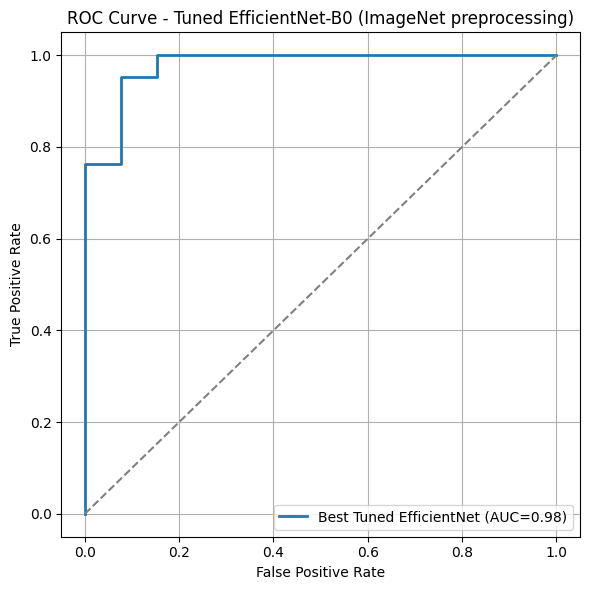

In [ ]:
# Step 9 — Plot ROC for the best tuned model
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, lw=2, label=f"Best Tuned EfficientNet (AUC={roc_auc:.2f})")
plt.plot([0,1], [0,1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned EfficientNet-B0 (ImageNet preprocessing)")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()


## 6. Saving the Best Model
The tuned EfficientNet-B0 (Model 5) is saved along with its hyperparameters and test metrics.

In [ ]:
# Findings: Best hyperparameter configuration
# batch_size: 8
# dropout: 0.2
# lr: 0.0003
# weight_decay: 0.0005
# unfreeze_blocks: 2

# Interpretation

# Small batch size (8) → better generalization on small medical datasets
# Lower LR (3e-4) → stable fine-tuning of pretrained weights
# Moderate weight decay → prevents overfitting
# Dropout 0.2 → just enough regularization (not too aggressive)
# Unfreeze last 2 EfficientNet blocks → perfect balance between preserving ImageNet features and adapting to brain MRI patterns

# save the model
# brain_mri_binary/
# └── final_model/
  #  ├── effnet_b0_tuned_weights.pt
  #  ├── effnet_b0_tuned_config.json
  #  ├── effnet_b0_metrics.json
  #  └── README.txt   (optional)

# Step 1 — Save the model weights/Architecture

from torchvision import models
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


weights_eff = models.EfficientNet_B0_Weights.DEFAULT
model_best = models.efficientnet_b0(weights=weights_eff)

model_best.classifier[1] = nn.Linear(
    model_best.classifier[1].in_features, 2
)

model_best = model_best.to(device)




Using device: cpu


In [ ]:
# Step 2 — Save the hyperparameter configuration (VERY IMPORTANT)

import os
import json

# 1️⃣ Define model directory (same place as model weights)
MODEL_DIR = "brain_mri_binary/final_model"
os.makedirs(MODEL_DIR, exist_ok=True)

# 2️⃣ Best hyperparameter configuration (from tuning)
best_config = {
    "model": "EfficientNet-B0",
    "preprocessing": "ImageNet / EfficientNet official transforms",
    "batch_size": 8,
    "dropout": 0.2,
    "learning_rate": 0.0003,
    "weight_decay": 0.0005,
    "unfreeze_blocks": 2,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss (class-weighted)",
    "input_size": [3, 224, 224],
    "dataset": "Brain MRI Binary Tumor Dataset",
    "task": "Binary classification (Tumor vs No Tumor)"
}

# 3️⃣ Save config
config_path = os.path.join(MODEL_DIR, "effnet_b0_tuned_config.json")

with open(config_path, "w") as f:
    json.dump(best_config, f, indent=4)

print("Hyperparameter config saved to:", config_path)


Hyperparameter config saved to: brain_mri_binary/final_model/effnet_b0_tuned_config.json


In [ ]:
# Step 3 — Save final test metrics
metrics = {
    "accuracy": 0.9411764705882353,
    "f1": 0.9545454545454546,
    "roc_auc": 0.978021978021978,
    "confusion_matrix": [[11, 2], [0, 21]],
    "notes": "No false negatives; high sensitivity suitable for screening"
}

metrics_path = os.path.join(MODEL_DIR, "effnet_b0_metrics.json")

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print(" Test metrics saved to:", metrics_path)


 Test metrics saved to: brain_mri_binary/final_model/effnet_b0_metrics.json


In [ ]:
# Step 4 —  README
readme_path = os.path.join(MODEL_DIR, "README.txt")

with open(readme_path, "w") as f:
    f.write(
        "Final Tuned EfficientNet-B0 Model\n"
        "================================\n\n"
        "Dataset: Brain MRI Binary Tumor Dataset\n"
        "Task: Tumor vs No Tumor classification\n\n"
        "Highlights:\n"
        "- Hyperparameter tuned EfficientNet-B0\n"
        "- Official ImageNet preprocessing\n"
        "- ROC-AUC ≈ 0.98\n"
        "- No false negatives on test set\n\n"
        "Intended use: Assistive screening tool (not diagnostic)\n"
    )

print(" README saved")


 README saved


## 7. Explainable AI (Grad-CAM, Integrated Gradients, SHAP)
These methods show which parts of each MRI the model relied on, using test-set examples of true positives, true negatives, false positives and false negatives.

> **Known issue:** `model_best` in Section 6 is built from EfficientNet-B0 but is **not loaded with the tuned weights**, so the maps below come from an untrained classification head (21/34 test images correct, versus 32/34 for the tuned model).
> **Planned fix:** save the tuned `state_dict` after Model 5, load it into `model_best`, and re-run this section.

In [ ]:
# XAI answers three questions:
   # Where is the model looking in the MRI?
   # Why did it predict tumor vs no tumor?
   # Can we trust that it’s not using artifacts or shortcuts?
# Which Method is better?

   # Grad-CAM → spatial focus (tumor region?)
   # Integrated Gradients → pixel-level attribution
   # SHAP → global + local feature contribution

# STEP 1 — Select representative test samples for Grad-CAM
    # True positive: actual=tumor present, predicted=tumor present = Correct tumor detection
    # True Negative: actual= no tumor, predicted= no tumor = Correct no-tumor detection
    # False Positive: actual= no tumor, predicted= tumor present = False alarm/Wrong flag
    # False Negative: actual= tumor present, predicted= no tumor = Missed tumor (MOST DANGEROUS)
                     #   TP     |      FN
                     #   FP     |      TN
# True positives and true negatives represent correct predictions
# While false positives indicate false alarms and false negatives represent missed tumors, the most critical error in medical diagnosis
# Sensitivity / Recall / TPR = How many actual tumors did we catch? TP/(TP+FN)
# Specificity / TNR = How many healthy cases did we correctly dismiss? TN/(TN+FP)
# Precision = When the model says tumor, how often is it right?(TP/TP+FP)


In [ ]:
# Explainable AI (XAI) refers to a set of methods and techniques that make a machine-learning model’s decisions understandable to humans.
# XAI helps answer: “Why did the model predict tumor?”, “Which parts of the MRI influenced this decision?”, “Can clinicians trust this prediction?”
# XAI explains how and why a model reaches a decision.
# XAI answers Is the model focusing on the tumor region? Or is it focusing on the skull, background, or artifacts?
# XAI helps verify if The model learned medically relevant features Not scanner noise, labels, or borders
# XAI helps explain: False Positives (FP): Why did the model hallucinate a tumor? False Negatives (FN): Why did it miss an actual tumor?
# XAI helps you show that: “Even though the model is complex, its decisions are grounded in meaningful image regions
# Grad-CAM................................Where is the model looking?
# Integrated Gradients...................	Which pixels influence the decision?
# SHAP...................................	How much does each region contribute?
# Explainable AI allows us to open the black box of deep learning and visually verify that the model is making decisions based on meaningful tumor regions
# in brain MRI scans rather than irrelevant patterns

# XAI will be primarily done on the TEST dataset, but selectively, not on every image
# because Test data is unseen by the model, Represents real-world performance, Avoids explanation bias from training data,
# And Matches how clinicians would use the model in practice. All figures, conclusions, and claims should be based on TEST data XAI

In [ ]:
# Use XAI on TEST dataset and Representative samples only (TP,TN,FP,FN)
# Explainable AI analysis was conducted on the final hyperparameter-tuned EfficientNet-B0 model, which achieved the best performance on the held-out test set.
# This ensures that explanations reflect the behavior of the deployed model rather than intermediate experimental models.


In [ ]:
# Make sure the model and weights are loaded
model_best.eval()
print("Model ready:", type(model_best))


Model ready: <class 'torchvision.models.efficientnet.EfficientNet'>


In [ ]:
# Make sure the dataset paths are correct (use your splits/test)
# Do NOT use brain_mri_binary/brain_tumor_dataset for XAI
# Always use splits/test so explanations correspond to reported metrics.
test_dir = "brain_mri_binary/splits/test"




In [ ]:
# Define XAI transforms (match EfficientNet ImageNet preprocessing)
from torchvision import models

weights_eff = models.EfficientNet_B0_Weights.DEFAULT
xai_tfms = weights_eff.transforms()


In [ ]:
 # Confirm class mapping (must match your evaluation)
from torchvision import datasets

test_ds = datasets.ImageFolder(test_dir, transform=xai_tfms)
print("test class_to_idx:", test_ds.class_to_idx)


test class_to_idx: {'no': 0, 'yes': 1}


In [ ]:
# Check full test class counts
import numpy as np
targets = np.array(test_ds.targets)
unique, counts = np.unique(targets, return_counts=True)
print("Class counts in test:", dict(zip(unique, counts)))
print("class_to_idx:", test_ds.class_to_idx)


Class counts in test: {np.int64(0): np.int64(13), np.int64(1): np.int64(21)}
class_to_idx: {'no': 0, 'yes': 1}


In [ ]:
# Build Test Loader
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_ds,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Sanity check
x, y = next(iter(test_loader))
print("x:", x.shape, x.dtype)
print("y:", y.unique())


x: torch.Size([8, 3, 224, 224]) torch.float32
y: tensor([0])


In [ ]:
# Check more than one batch
for i, (x, y) in enumerate(test_loader):
    print(i, "unique labels:", torch.unique(y))
    if i == 5:
        break


0 unique labels: tensor([0])
1 unique labels: tensor([0, 1])
2 unique labels: tensor([1])
3 unique labels: tensor([1])
4 unique labels: tensor([1])


In [ ]:
# Confirm the dataset contains both folders
import os
print("Folders:", os.listdir(test_dir))
print("No files:", len(os.listdir(os.path.join(test_dir, "no"))))
print("Yes files:", len(os.listdir(os.path.join(test_dir, "yes"))))


Folders: ['yes', 'no']
No files: 13
Yes files: 21


In [ ]:
#Step A — Collect test predictions WITH file paths
import torch
import numpy as np

def collect_test_predictions(model, test_ds, test_loader, device):
    model.eval()

    # IMPORTANT: ImageFolder keeps paths here (ordered)
    paths = [p for (p, _) in test_ds.samples]

    results = []
    idx_offset = 0

    with torch.no_grad():
        for x, y in test_loader:
            b = x.size(0)
            x = x.to(device)

            logits = model(x)
            probs = torch.softmax(logits, dim=1).cpu().numpy()  # [B,2]
            pred = np.argmax(probs, axis=1)                     # [B]
            prob_yes = probs[:, 1]                              # [B]

            y_np = y.numpy()

            for i in range(b):
                py = float(prob_yes[i])
                results.append({
                    "path": paths[idx_offset + i],
                    "true": int(y_np[i]),
                    "pred": int(pred[i]),
                    "prob_yes": py,
                    "confidence": float(max(py, 1.0 - py))
                })

            idx_offset += b

    return results

# Run it
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_best = model_best.to(device).eval()

preds = collect_test_predictions(model_best, test_ds, test_loader, device)
print("Collected predictions:", len(preds))
print("Example:", preds[0])


Collected predictions: 34
Example: {'path': 'brain_mri_binary/splits/test/no/12 no.jpg', 'true': 0, 'pred': 1, 'prob_yes': 0.521140456199646, 'confidence': 0.521140456199646}


In [ ]:
# Step B — Split into TP/TN/FP/FN buckets
def split_confusion_buckets(preds, positive_label=1):
    TP, TN, FP, FN = [], [], [], []
    for r in preds:
        t, p = r["true"], r["pred"]
        if t == positive_label and p == positive_label:
            TP.append(r)
        elif t != positive_label and p != positive_label:
            TN.append(r)
        elif t != positive_label and p == positive_label:
            FP.append(r)
        else:
            FN.append(r)
    return TP, TN, FP, FN

TP, TN, FP, FN = split_confusion_buckets(preds, positive_label=1)
print("Counts:", {"TP": len(TP), "TN": len(TN), "FP": len(FP), "FN": len(FN)})


Counts: {'TP': 15, 'TN': 6, 'FP': 7, 'FN': 6}


In [ ]:
# Step C — Pick representative samples (best for XAI)
def pick_representatives(TP, TN, FP, FN, k_tp=3, k_tn=3, k_fp=2, k_fn=2):
    TP_sorted = sorted(TP, key=lambda r: r["prob_yes"], reverse=True)
    TN_sorted = sorted(TN, key=lambda r: r["prob_yes"])
    FP_sorted = sorted(FP, key=lambda r: r["prob_yes"], reverse=True)
    FN_sorted = sorted(FN, key=lambda r: r["prob_yes"])

    return {
        "TP": TP_sorted[:k_tp],
        "TN": TN_sorted[:k_tn],
        "FP": FP_sorted[:min(k_fp, len(FP_sorted))],
        "FN": FN_sorted[:min(k_fn, len(FN_sorted))],
    }

reps = pick_representatives(TP, TN, FP, FN, k_tp=3, k_tn=3, k_fp=2, k_fn=2)

for k, v in reps.items():
    print(k, len(v))
    for r in v:
        print("  ", r["path"], "| true:", r["true"], "pred:", r["pred"], "prob_yes:", round(r["prob_yes"], 3))


TP 3
   brain_mri_binary/splits/test/yes/Y154.jpg | true: 1 pred: 1 prob_yes: 0.697
   brain_mri_binary/splits/test/yes/Y258.JPG | true: 1 pred: 1 prob_yes: 0.661
   brain_mri_binary/splits/test/yes/Y170.JPG | true: 1 pred: 1 prob_yes: 0.646
TN 3
   brain_mri_binary/splits/test/no/37 no.jpg | true: 0 pred: 0 prob_yes: 0.367
   brain_mri_binary/splits/test/no/22 no.jpg | true: 0 pred: 0 prob_yes: 0.414
   brain_mri_binary/splits/test/no/no 99.jpg | true: 0 pred: 0 prob_yes: 0.422
FP 2
   brain_mri_binary/splits/test/no/4 no.jpg | true: 0 pred: 1 prob_yes: 0.605
   brain_mri_binary/splits/test/no/23 no.jpg | true: 0 pred: 1 prob_yes: 0.582
FN 2
   brain_mri_binary/splits/test/yes/Y3.jpg | true: 1 pred: 0 prob_yes: 0.386
   brain_mri_binary/splits/test/yes/Y16.JPG | true: 1 pred: 0 prob_yes: 0.426


In [ ]:
# Step D — Define helpers: denorm + load/preprocess + overlay
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

# --- Denormalize (ImageNet stats) for display ---
def denorm_imagenet(x_chw):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    x = x_chw.detach().cpu() * std + mean
    x = x.clamp(0, 1)
    return x.permute(1,2,0).numpy()  # [H,W,3]

# --- Load + preprocess one image (uses your xai_tfms) ---
def load_and_preprocess(path):
    img = Image.open(path).convert("RGB")
    x = xai_tfms(img)               # [3,224,224] normalized
    img_rgb = denorm_imagenet(x)    # [224,224,3] for plotting
    return x.unsqueeze(0), img_rgb  # [1,3,224,224], [224,224,3]

# --- Overlay helper ---
def overlay_heatmap(img_rgb, cam_01, alpha=0.38):
    cam_rgb = plt.cm.jet(cam_01)[..., :3]          # [H,W,3]
    overlay = (1 - alpha) * img_rgb + alpha * cam_rgb
    return np.clip(cam_rgb, 0, 1), np.clip(overlay, 0, 1)


In [ ]:
# Step E — Grad-CAM implementation (EfficientNet-B0)
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.fwd_handle = target_layer.register_forward_hook(self._save_activations)
        self.bwd_handle = target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, inp, out):
        self.activations = out

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def remove_hooks(self):
        self.fwd_handle.remove()
        self.bwd_handle.remove()

    def __call__(self, x, class_idx=None):
        """
        x: [1,3,224,224] on device
        class_idx: target class for explanation; None -> predicted class
        returns cam: [224,224] in [0,1], pred_idx, prob_yes
        """
        self.model.zero_grad(set_to_none=True)

        logits = self.model(x)
        probs = F.softmax(logits, dim=1)

        pred_idx = int(torch.argmax(probs, dim=1).item())
        prob_yes = float(probs[:, 1].item())  # assumes yes index=1

        if class_idx is None:
            class_idx = pred_idx

        score = logits[:, class_idx].sum()
        score.backward(retain_graph=False)

        A = self.activations.detach()   # [1,C,h,w]
        G = self.gradients.detach()     # [1,C,h,w]

        weights = G.mean(dim=(2,3), keepdim=True)   # [1,C,1,1]
        cam = (weights * A).sum(dim=1)              # [1,h,w]
        cam = F.relu(cam)

        # normalize
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        # upsample to input size
        cam = F.interpolate(cam.unsqueeze(1), size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()           # [224,224]

        return cam, pred_idx, prob_yes


In [ ]:
# Step F — Choose EfficientNet target layer (best default)
model_best.eval()
target_layer = model_best.features[-1]   # good default for EfficientNet-B0
cam_engine = GradCAM(model_best, target_layer)


In [ ]:
# Step G — Plot Grad-CAM for TP / TN / FP / FN
idx_to_class = {v:k for k,v in test_ds.class_to_idx.items()}

def show_gradcam_group(samples, title, explain="pred", max_show=3):
    """
    explain:
      "pred" -> explain predicted class
      "true" -> explain true class (useful for FP/FN)
    """
    if len(samples) == 0:
        print(title, "(no samples)")
        return

    samples = samples[:max_show]
    n = len(samples)

    plt.figure(figsize=(12, 4*n))
    for i, r in enumerate(samples):
        x, img_rgb = load_and_preprocess(r["path"])
        x = x.to(device)

        if explain == "true":
            class_idx = int(r["true"])
        else:
            class_idx = None  # predicted class

        cam, pred_idx, prob_yes = cam_engine(x, class_idx=class_idx)
        heat, overlay = overlay_heatmap(img_rgb, cam, alpha=0.38)

        true_name = idx_to_class[int(r["true"])]
        pred_name = idx_to_class[int(r["pred"])]

        row = i*3
        plt.subplot(n, 3, row+1)
        plt.imshow(img_rgb); plt.axis("off")
        plt.title(f"Original\nT:{true_name}  P:{pred_name}\nP(yes)={prob_yes:.2f}", fontsize=10)

        plt.subplot(n, 3, row+2)
        plt.imshow(heat); plt.axis("off")
        plt.title(f"Grad-CAM ({explain})", fontsize=10)

        plt.subplot(n, 3, row+3)
        plt.imshow(overlay); plt.axis("off")
        plt.title("Overlay", fontsize=10)

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

# TP/TN: explain predicted class
show_gradcam_group(reps["TP"], "Grad-CAM — True Positives (Tumor correctly detected)", explain="pred", max_show=3)
show_gradcam_group(reps["TN"], "Grad-CAM — True Negatives (No tumor correctly detected)", explain="pred", max_show=3)

# FP/FN: show both explanations (pred vs true) — very informative
show_gradcam_group(reps["FP"], "Grad-CAM — False Positives (Explain PRED class)", explain="pred", max_show=2)
show_gradcam_group(reps["FP"], "Grad-CAM — False Positives (Explain TRUE class)", explain="true", max_show=2)

show_gradcam_group(reps["FN"], "Grad-CAM — False Negatives (Explain PRED class)", explain="pred", max_show=2)
show_gradcam_group(reps["FN"], "Grad-CAM — False Negatives (Explain TRUE class)", explain="true", max_show=2)


In [ ]:
# Step H — Cleanup hooks
cam_engine.remove_hooks()


In [ ]:
# Guide of Interpretation
# Good model behavior: heatmap/overlay highlights the suspected tumor region or abnormal tissue.
# False positives: heatmap might focus on skull edges, bright artifacts, or non-tumor structures.
# False negatives: heatmap misses subtle lesion region and focuses elsewhere.

In [ ]:
# Step I — Integrated Gradients setup + plotting (Captum)
# Install + import Captum (run once)
!pip -q install captum


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 103.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
shap 0.50.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import IntegratedGradients

model_best.eval()
ig = IntegratedGradients(model_best)


In [ ]:
# 2) IG heatmap function
def integrated_gradients_map(x, target_idx, n_steps=50):
    """
    x: [1,3,224,224] normalized tensor on device
    target_idx: int class index (0=no, 1=yes)
    returns: heatmap [224,224] in [0,1]
    """
    baseline = torch.zeros_like(x)  # black baseline in normalized space

    attributions = ig.attribute(
        inputs=x,
        baselines=baseline,
        target=target_idx,
        n_steps=n_steps
    )  # [1,3,224,224]

    # Convert to 2D heatmap
    attr = attributions.squeeze(0).abs().mean(dim=0)  # [224,224]
    attr = attr - attr.min()
    attr = attr / (attr.max() + 1e-8)

    return attr.detach().cpu().numpy()


In [ ]:
# 3) Plot IG for TP/TN/FP/FN reps

# This reuses your load_and_preprocess() and overlay_heatmap() from the Grad-CAM step.
idx_to_class = {v:k for k,v in test_ds.class_to_idx.items()}

def show_ig_group(samples, title, explain="pred", max_show=3, n_steps=50):
    """
    explain:
      "pred" -> explain predicted class attribution
      "true" -> explain true class attribution (useful for FP/FN)
    """
    if len(samples) == 0:
        print(title, "(no samples)")
        return

    samples = samples[:max_show]
    n = len(samples)

    plt.figure(figsize=(12, 4*n))
    for i, r in enumerate(samples):
        x, img_rgb = load_and_preprocess(r["path"])
        x = x.to(device)

        if explain == "true":
            target_idx = int(r["true"])
        else:
            target_idx = int(r["pred"])

        heat_ig = integrated_gradients_map(x, target_idx=target_idx, n_steps=n_steps)
        heat, overlay = overlay_heatmap(img_rgb, heat_ig, alpha=0.38)

        true_name = idx_to_class[int(r["true"])]
        pred_name = idx_to_class[int(r["pred"])]

        row = i*3
        plt.subplot(n, 3, row+1)
        plt.imshow(img_rgb); plt.axis("off")
        plt.title(f"Original\nT:{true_name}  P:{pred_name}\nP(yes)={r['prob_yes']:.2f}", fontsize=10)

        plt.subplot(n, 3, row+2)
        plt.imshow(heat); plt.axis("off")
        plt.title(f"Integrated Gradients ({explain})", fontsize=10)

        plt.subplot(n, 3, row+3)
        plt.imshow(overlay); plt.axis("off")
        plt.title("Overlay", fontsize=10)

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


# TP/TN: explain predicted class
show_ig_group(reps["TP"], "Integrated Gradients — True Positives", explain="pred", max_show=3, n_steps=50)
show_ig_group(reps["TN"], "Integrated Gradients — True Negatives", explain="pred", max_show=3, n_steps=50)

# FP/FN: show both pred and true explanations
show_ig_group(reps["FP"], "Integrated Gradients — False Positives (Explain PRED class)", explain="pred", max_show=2, n_steps=50)
show_ig_group(reps["FP"], "Integrated Gradients — False Positives (Explain TRUE class)", explain="true", max_show=2, n_steps=50)

show_ig_group(reps["FN"], "Integrated Gradients — False Negatives (Explain PRED class)", explain="pred", max_show=2, n_steps=50)
show_ig_group(reps["FN"], "Integrated Gradients — False Negatives (Explain TRUE class)", explain="true", max_show=2, n_steps=50)


In [ ]:
# interpret IG (quick guidance)

# IG tends to highlight fine-grained pixel regions contributing to the class.
# Compared to Grad-CAM:Grad-CAM is “where the model looked” (coarse, spatial).IG is “which pixels pushed the prediction” (more detailed, sometimes noisier).
# FP / FN IG maps are very valuable for diagnosing why the model failed.

In [ ]:
!pip -q install "shap<0.50"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 15.2 MB/s eta 0:00:00


In [ ]:
# SHAP in Colab can break due to the NumPy ≥2 requirement depending on versions.
# On CPU, SHAP is the slowest, so we’ll run it only on a handful of reps.
# CPU-safe SHAP workflow

# Step J — SHAP (GradientExplainer) with Overlays
# J0) Install a compatible SHAP version (important)
!pip -q install "shap<0.50"
# J1) Imports + background dataset
import shap
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets

# Build val dataset with SAME transforms used for model
val_ds = datasets.ImageFolder(val_dir, transform=xai_tfms)
print("val class_to_idx:", val_ds.class_to_idx)


val class_to_idx: {'no': 0, 'yes': 1}


In [ ]:
# Build background tensor (small sample)
def build_shap_background(ds, n=8):
    xs = []
    for i in range(min(n, len(ds))):
        x, _ = ds[i]               # [3,224,224] normalized
        xs.append(x)
    bg = torch.stack(xs, dim=0)    # [n,3,224,224]
    return bg

background = build_shap_background(val_ds, n=8).to(device)
print("background shape:", background.shape)


background shape: torch.Size([8, 3, 224, 224])


In [ ]:
# J2) Wrap model to output a single scalar (prob_yes)

# SHAP works best when the model output is [B, 1] instead of [B].
class YesProbWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x):
        logits = self.model(x)
        probs = torch.softmax(logits, dim=1)
        return probs[:, 1:2]  # [B,1] probability of "yes"

wrapped = YesProbWrapper(model_best).to(device).eval()


In [ ]:
# J3) Create the SHAP explainer (GradientExplainer)
explainer = shap.GradientExplainer(wrapped, background)


In [ ]:
# J4) SHAP heatmap function

# This returns a [224,224] heatmap in [0,1].
def shap_map(x):
    """
    x: torch tensor [1,3,224,224] on device
    returns: numpy heatmap [224,224] in [0,1]
    """
    shap_vals = explainer.shap_values(x)

    # shap_vals is typically a list with one element for single-output models
    if isinstance(shap_vals, list):
        sv = shap_vals[0]   # expected [1,3,224,224]
    else:
        sv = shap_vals

    # Convert to heatmap: mean abs over channels
    sv = np.abs(sv).mean(axis=1).squeeze(0)  # [224,224]

    sv = sv - sv.min()
    sv = sv / (sv.max() + 1e-8)
    return sv


In [ ]:
import numpy as np

def ensure_hw3(img):
    """
    Force image into shape (H,W,3) for plt.imshow().
    Handles (H,W,3), (1,H,W,3), (H,W,1,3), (3,H,W), etc.
    """
    img = np.array(img)

    # channel-first -> channel-last
    if img.ndim == 3 and img.shape[0] == 3 and img.shape[-1] != 3:
        img = np.transpose(img, (1,2,0))

    # (H,W,1,3) -> (H,W,3)
    if img.ndim == 4 and img.shape[2] == 1 and img.shape[3] == 3:
        img = img[:, :, 0, :]

    # (1,H,W,3) -> (H,W,3)
    if img.ndim == 4 and img.shape[0] == 1 and img.shape[-1] == 3:
        img = img[0]

    if not (img.ndim == 3 and img.shape[-1] == 3):
        raise ValueError(f"ensure_hw3: invalid shape {img.shape}")

    return img


def ensure_hw(heat):
    """
    Force heatmap into shape (H,W).
    Handles (H,W), (1,H,W), (H,W,1), (1,H,W,1), etc.
    """
    heat = np.array(heat)

    if heat.ndim == 4 and heat.shape[0] == 1:
        heat = heat[0]
    if heat.ndim == 3 and heat.shape[-1] == 1:
        heat = heat[..., 0]
    if heat.ndim == 3 and heat.shape[0] == 1:
        heat = heat[0]

    if heat.ndim != 2:
        raise ValueError(f"ensure_hw: invalid shape {heat.shape}")

    return heat


In [ ]:
import matplotlib.pyplot as plt

def overlay_heatmap(img_rgb, heat_01, alpha=0.38, cmap="jet"):
    img_rgb = ensure_hw3(img_rgb)     # (H,W,3)
    heat_01 = ensure_hw(heat_01)      # (H,W)

    cm = plt.get_cmap(cmap)
    heat_rgb = cm(heat_01)[..., :3]   # (H,W,3)

    overlay = (1 - alpha) * img_rgb + alpha * heat_rgb
    return np.clip(heat_rgb, 0, 1), np.clip(overlay, 0, 1)


In [ ]:
def load_and_preprocess(path):
    img = Image.open(path).convert("RGB")
    x = xai_tfms(img)               # [3,224,224] normalized
    img_rgb = denorm_imagenet(x)    # should be [224,224,3]
    img_rgb = ensure_hw3(img_rgb)   # ✅ enforce
    return x.unsqueeze(0), img_rgb


In [ ]:
def show_shap_group(samples, title, max_show=3):
    if len(samples) == 0:
        print(title, "(no samples)")
        return

    samples = samples[:max_show]
    n = len(samples)

    plt.figure(figsize=(12, 4*n))
    for i, r in enumerate(samples):
        x, img_rgb = load_and_preprocess(r["path"])
        x = x.to(device)

        hm = shap_map(x)
        hm = ensure_hw(hm)

        heat, overlay = overlay_heatmap(img_rgb, hm, alpha=0.38)

        true_name = idx_to_class[int(r["true"])]
        pred_name = idx_to_class[int(r["pred"])]

        row = i*3
        plt.subplot(n, 3, row+1)
        plt.imshow(ensure_hw3(img_rgb)); plt.axis("off")
        plt.title(f"Original\nT:{true_name}  P:{pred_name}\nP(yes)={r['prob_yes']:.2f}", fontsize=10)

        plt.subplot(n, 3, row+2)
        plt.imshow(ensure_hw3(heat)); plt.axis("off")
        plt.title("SHAP (GradientExplainer)", fontsize=10)

        plt.subplot(n, 3, row+3)
        plt.imshow(ensure_hw3(overlay)); plt.axis("off")
        plt.title("Overlay", fontsize=10)

    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


In [ ]:
show_shap_group(reps["TP"], "SHAP — True Positives", max_show=2)
show_shap_group(reps["TN"], "SHAP — True Negatives", max_show=2)
show_shap_group(reps["FP"], "SHAP — False Positives", max_show=1)
show_shap_group(reps["FN"], "SHAP — False Negatives", max_show=1)


In [ ]:
# How to interpret SHAP vs Grad-CAM vs IG
# Grad-CAM: where the CNN focuses spatially (coarse, intuitive)
# Integrated Gradients: pixel attribution sensitivity (detailed but can be noisy)
# SHAP: attribution relative to a baseline distribution (often smoother and more “global”)
# If all three highlight similar regions on TP/TN, that’s a strong trust signal.

In [ ]:
# cam_engine.remove_hooks()
cam_engine.remove_hooks()
